# Steering an LLM to vary its search algorithms: a de-commitment steering screen on Qwen3-8B

**Artifact:** experiment 4, `method.py`. **Model:** Qwen3-8B with thinking off.

**The question.** Ask an LLM to "write a shortest-path function" and it almost always writes the same algorithm. Can we push it, from *inside* the network, toward other **correct** algorithms?

**The candidate mechanism: de-commitment.** At the last prompt token (the *read position* **R**), the model may already have committed to one algorithm. A prompt that says *"list 10 approaches, do not implement"* keeps many options open, while *"implement it"* commits. So the difference of their mean residual states,

$$d_{dc} = \text{mean}(h_R \mid \text{LIST}) - \text{mean}(h_R \mid \text{IMPLEMENT}),$$

is a candidate "keep your options open" direction. During generation the method adds $c\,\lVert h\rVert\,\hat d_{dc}$ at layer $L^*=18$, at R and at every generated token. It then asks whether the **diversity of correct programs** rises. Diversity is measured by the Hill-1 number (exp of the Shannon entropy) of the algorithm labels among the programs that pass the hidden tests.

**Two tasks with known algorithm catalogues.**
* T1, grid path: BFS / DFS / bidirectional BFS / IDDFS / A* / Dijkstra.
* T2, weighted shortest path: Dijkstra / Bellman-Ford (incl. SPFA) / bidirectional Dijkstra / Floyd-Warshall / Dial.

**Labels.** A sandboxed run of the hidden tests, a runtime tracer and AST rules label each program; an LLM judge settles disagreements.

**Headline of the full run.**
* T1 is 100 % BFS in every arm except prompt bans.
* On T2, steering at $c^*=0.25$ moves correct programs from Dijkstra to Bellman-Ford (rarefied ΔHill-1 ≈ +0.65).
* A norm-matched **random** direction does almost the same (+0.59), so the gain is *not* specific to $d_{dc}$.
* Screen verdict: **PARTIAL**.

### What this notebook runs
`method.py` is an orchestrator. It runs 17 stages, each in its own process. The GPU stages need Qwen3-8B on a 20 GB GPU for about 2 hours. This notebook keeps the stage order. Every CPU stage runs **live, from the original code**, and the outputs of the GPU stages are **loaded** from `mini_demo_data.json`.

| `method.py` stage | what it does | in this notebook |
|---|---|---|
| `states` (GPU) | residual states at R for 930 prompts, layers 8–28 | loaded: T2 states at L* = 18; LIST/IMPLEMENT also at 8, 13, 23, 28 |
| `directions` | $d_{dc}$, layer selection, diagnostics, commitment test | **live** |
| `vllm1/2/3` (GPU) | baseline, enumerate, ban, mention, succession samples | loaded (labelled programs) |
| `steer` (GPU) | HF steering arms with common random numbers; the c* rule | **live**: the steering hook on real Qwen3-8B states, and the c* rule. The generations are loaded |
| `label` | hidden tests + runtime tracer (sandbox) + AST rules + judge | **live**: the AST rules. The test and tracer results are loaded |
| `commit`, `succ` | modal mode, sha256-committed forecasts | **live**: hash verification and scoring |
| `analyze` | statistics, buy table, screen verdict | **live** |
| `meta`, `prompts`, `tasks`, `gate` | records, paraphrases, hidden tests + R0 gate, labeller gate (LLM judges) | not run; their outputs are in the data |

**Data: one dataset.** T2 (weighted shortest path), all **100 common-random-number slots** (10 prompt paraphrases × 10 seeds). Each slot holds the labelled program of all 19 arms.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original scripts log through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, scikit-learn, statsmodels, matplotlib, torch — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'statsmodels==0.14.6',
         'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# imports used by the original scripts (common.py, analysis/*.py, labeller/ast_rules.py, gpu/hf_steer.py)
import ast
import hashlib
import json
import math
import re
import sys
import time
from collections import Counter

import numpy as np
import torch
from loguru import logger
from sklearn.metrics import roc_auc_score

# notebook additions: decoding the shipped states, the stats namespace, plotting
import base64
import types
import zlib

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


## Configuration

Every tunable parameter is set here. The values are scaled down so that the notebook runs in a few minutes on a CPU, and each comment gives the original value. The original seeds are kept, so with the original values these match the full run exactly:
* the layer-selection scores and the direction diagnostics;
* the commitment-test nulls;
* the ΔHill CIs of the HF steering arms.

The vLLM baseline has 100 of its 200 samples here, so numbers that use it differ a little.

In [5]:
# ---- tunable parameters: demo values (original values in the comments) ----
TASKS_DEMO = ["T2"]                 # tasks shipped in mini_demo_data.json (original: TASKS = ["T1", "T2"])
SEL_LAYERS = [8, 13, 18, 23, 28]    # layer-selection candidates (original: LAYERS = 8..28, all 21; only these 5 are shipped)
N_BOOT = 2000                       # bootstrap resamples behind every 90% CI (original: NB = 2000)
N_RAREFY = 1000                     # rarefaction repeats of each rarefied Hill-1 point estimate (original: 1000)
N_RAREFY_BOOT = 30                  # rarefaction repeats inside each bootstrap replicate (original: 30)
N_MC = 20000                        # Monte-Carlo permutations of the 2 x K exact test (original: 20000)
N_SHIFT_NULL = 2000                 # random 10/10 paraphrase splits in the commitment-test null (original: 2000)
N_NULL_DIRS = 1000                  # random directions in the share-of-shift nulls (original: 1000)
N_SPLIT_HALF = 200                  # split-half repeats in the direction diagnostics (original: 200)
AST_MAX_PROGRAMS = 1499             # programs re-labelled live by the AST rules (original: every program; 1,499 here)

## Shared constants (`common.py`)

These are the task specs, the algorithm catalogues and the seeding helper. They are copied from `common.py`; only `LAYERS` and `TASKS` point at the demo config. `stable_hash` derives every seed (HF sampling batches, random directions, bootstraps) from a sha256 of its parts, so the notebook re-creates the exact random directions of the full run.

In [6]:
MODEL_ID = "Qwen/Qwen3-8B"
N_LAYERS = 36
LAYERS = SEL_LAYERS                  # candidate read/steer layers (original: list(range(8, 29)), below 0.8 L)
GRID_C = [0.25, 0.5, 1.0, 1.5]        # steering coefficient grid (c = 0 is the zero-strength control)
PAD_ID = 151643
EOS_IDS = [151645, 151643]

TASKS = TASKS_DEMO                   # original: ["T1", "T2"]

SPEC = {
    "T1": (
        "Task: write a Python function solve(grid, start, goal). grid is a list of equal-length strings in which . "
        "is an open cell and # is a wall; start and goal are (row, col) tuples of open cells. A move goes up, down, "
        "left or right to an open cell inside the grid. Return any valid path from start to goal as a list of "
        "(row, col) tuples that begins with start, ends with goal and in which consecutive cells are adjacent; "
        "return [] if goal cannot be reached. Grids have at most 30 rows and 30 columns. Use only the Python "
        "standard library. Return only one ```python code block containing solve."
    ),
    "T2": (
        "Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
        "edges is a list of (u, v, w) tuples with integer weights 0 <= w <= 100; parallel edges, self-loops and "
        "cycles may occur. Return the length of a shortest path from s to t as an int, or -1 if t is unreachable "
        "from s (0 when s == t). Use only the Python standard library. Return only one ```python code block "
        "containing solve."
    ),
}

# Catalogue modes per task (label ids) and the display names used inside ban / mention prompts.
CATALOGUE = {
    "T1": ["bfs", "dfs", "bidirectional_bfs", "iddfs", "astar", "dijkstra_unit"],
    "T2": ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"],
}
DISPLAY = {
    "T1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidirectional_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS",
        "astar": "A* search",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "the Bellman-Ford algorithm (including SPFA)",
        "bidirectional_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "the Floyd-Warshall algorithm",
        "dial": "Dial's algorithm (bucket queue)",
    },
}
DEFINITIONS = {
    "T1": {
        "bfs": "breadth-first search with a FIFO queue (deque or list.pop(0)), recursive or iterative",
        "dfs": "depth-first search with a LIFO stack or plain recursion, no outer depth-limit loop",
        "bidirectional_bfs": "two simultaneous breadth-first frontiers, one from start and one from goal, that meet",
        "iddfs": "iterative deepening: repeated depth-limited DFS from start with an increasing depth limit",
        "astar": "best-first search on a heap keyed by g+h or h with h = Manhattan distance to goal (A* or greedy best-first)",
        "dijkstra_unit": "uniform-cost search / Dijkstra on a heap keyed by path length g only (no heuristic)",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm with one priority queue (heap), nodes popped in non-decreasing distance",
        "bellman_ford_spfa": "Bellman-Ford edge relaxation in repeated passes, or SPFA (FIFO queue with re-enqueueing)",
        "bidirectional_dijkstra": "two Dijkstra searches, forward from s and backward from t on reversed edges, that meet",
        "floyd_warshall": "all-pairs Floyd-Warshall triple loop dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j])",
        "dial": "Dial's algorithm: Dijkstra with an array of buckets indexed by distance instead of a heap",
    },
}


def stable_hash(*parts: object) -> int:
    """Deterministic 31-bit seed from arbitrary parts (independent of PYTHONHASHSEED)."""
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16) % (2**31 - 1)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8", errors="replace")).hexdigest()


def setup_logger(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    # notebook: no rotating log file under logs/


def cond_name_steer(direction: str, coef: float, layer: int) -> str:
    return f"steer:{direction}:c={coef:g}:L={layer}"


setup_logger("method")

## The orchestrator (`method.py`)

The pipeline order is copied from `method.py`. Each stage there runs a script in its own process, and it skips any work already on disk. The table shows what each stage becomes in this notebook.

In [7]:
STAGES = ["meta", "prompts", "tasks", "states", "directions", "vllm1", "label", "steer", "label", "gate", "commit",
          "vllm2", "label", "succ", "vllm3", "label", "analyze"]
IN_NOTEBOOK = {
    "meta": "not run (protocol/deviation records)",
    "prompts": "loaded: prompt segments ship with the R-states",
    "tasks": "not run: hidden tests + R0 gate (all 12 references pass, all wrong programs fail)",
    "states": "loaded: Qwen3-8B residual states at R (GPU)",
    "directions": "LIVE: analysis/directions.py",
    "vllm1": "loaded: vLLM baseline + enumerate samples (GPU)",
    "label": "LIVE: labeller/ast_rules.py; sandbox test + tracer labels loaded",
    "steer": "LIVE: Steerer hook on real states + c* rule; HF generations loaded (GPU)",
    "gate": "not run: labeller gate with LLM judges (passed on T2 after 2 revision rounds)",
    "commit": "LIVE: modal mode + sha256 check of the committed forecasts",
    "vllm2": "loaded: ban + mention samples (GPU)",
    "succ": "LIVE: succession forecast verified with the ban forecast",
    "vllm3": "loaded: succession samples (GPU)",
    "analyze": "LIVE: analysis/stats.py + analysis/analyze.py",
}
for s in STAGES:
    print(f"  {s:<11s} {IN_NOTEBOOK[s]}")

  meta        not run (protocol/deviation records)
  prompts     loaded: prompt segments ship with the R-states
  tasks       not run: hidden tests + R0 gate (all 12 references pass, all wrong programs fail)
  states      loaded: Qwen3-8B residual states at R (GPU)
  directions  LIVE: analysis/directions.py
  vllm1       loaded: vLLM baseline + enumerate samples (GPU)
  label       LIVE: labeller/ast_rules.py; sandbox test + tracer labels loaded
  steer       LIVE: Steerer hook on real states + c* rule; HF generations loaded (GPU)
  label       LIVE: labeller/ast_rules.py; sandbox test + tracer labels loaded
  gate        not run: labeller gate with LLM judges (passed on T2 after 2 revision rounds)
  commit      LIVE: modal mode + sha256 check of the committed forecasts
  vllm2       loaded: ban + mention samples (GPU)
  label       LIVE: labeller/ast_rules.py; sandbox test + tracer labels loaded
  succ        LIVE: succession forecast verified with the ban forecast
  vllm3       loade

## Loading the shipped data: labelled samples and residual states

Each example is one common-random-number slot (paraphrase × seed). It keeps the `exp_gen_sol_out` fields of `method_out.json`: `output` is the label of the unsteered HF sample, and `predict_<arm>` is `label|pass/fail` for every other arm. Under `arms` it also keeps the full labelled sample of every arm. The cell below flattens the slots back into one row per sample, the layout of `data/samples.jsonl`.

The **R-states** are the residual-stream vectors of Qwen3-8B at the last prompt token, saved as float16 (4096-d). They cover every prompt *frame* (LIST, IMPLEMENT, ONE, LONGNAMES, SHORTNAMES, 50 paraphrases each) and every prompt *condition* (baseline, enumerate, list-all, ban:X, mention:X).

In [8]:
META = data["metadata"]
REF = META["reference_results"]      # numbers from the full run, for side-by-side comparison only
examples = data["datasets"][0]["examples"]

# one row per labelled sample, in the layout of data/samples.jsonl (restricted to the 100 CRN slots)
samples = []
for ex in examples:
    for cond, arm in ex["arms"].items():
        samples.append({"task": ex["metadata_task"], "condition": cond, "paraphrase_id": ex["metadata_paraphrase_id"],
                        "sample_id": ex["metadata_sample_id"], **arm})


def decode_states(b64: str, n: int, d: int) -> np.ndarray:
    """base64(zlib(float16 bytes)) -> [n_prompts, d_model], as stored in cache/hR_<task>_<group>.npy."""
    return np.frombuffer(zlib.decompress(base64.b64decode(b64)), dtype=np.float16).reshape(n, d)


HR = {g: {int(l): decode_states(s, v["n"], META["d_model"]) for l, s in v["layers"].items()}
      for g, v in data["r_states"].items()}
SEGMENTS = {g: v["segments"] for g, v in data["r_states"].items()}

print(f"{len(examples)} CRN slots -> {len(samples)} labelled samples in {len({r['condition'] for r in samples})} arms\n")
print(f"{'arm':<28s} {'engine':<6s} {'n':>4s} {'pass':>5s}  labels of correct programs")
for c in sorted({r["condition"] for r in samples}):
    rows = [r for r in samples if r["condition"] == c]
    cnt = Counter(r["label"] for r in rows if r["passed"])
    print(f"{c:<28s} {rows[0]['engine']:<6s} {len(rows):4d} {np.mean([r['passed'] for r in rows]):5.2f}  {dict(cnt.most_common())}")

print("\nR-states (prompts x d_model per layer):")
for g, v in HR.items():
    print(f"  {g:<28s} n={len(next(iter(v.values()))):3d}  layers={sorted(v)}")
print("\nExample prompt segments (each is followed by the task spec):")
for g in ("LIST", "IMPLEMENT", "baseline", "enumerate", "ban:dijkstra", "mention:dijkstra"):
    print(f"  {g:<17s} {SEGMENTS[g][0]!r}")
print("\nT2 spec:", SPEC["T2"])

100 CRN slots -> 1670 labelled samples in 19 arms

arm                          engine    n  pass  labels of correct programs
ban:dijkstra                 vllm    100  0.87  {'dijkstra': 49, 'bellman_ford_spfa': 38}
baseline                     vllm    100  0.88  {'dijkstra': 81, 'bellman_ford_spfa': 7}
enumerate                    vllm    100  0.82  {'dijkstra': 80, 'bellman_ford_spfa': 2}
enumerate@1024               vllm    100  0.82  {'dijkstra': 80, 'bellman_ford_spfa': 2}
mention:dijkstra             vllm    100  0.94  {'dijkstra': 92, 'bellman_ford_spfa': 2}
steer:breadth:c=0.25:L=18    hf      100  0.60  {'bellman_ford_spfa': 31, 'dijkstra': 28, 'dial': 1}
steer:dc:c=0.25:L=18         hf      100  0.78  {'bellman_ford_spfa': 54, 'dijkstra': 23, 'other': 1}
steer:dc:c=0.375:L=18        hf      100  0.67  {'bellman_ford_spfa': 47, 'dijkstra': 19, 'other': 1}
steer:dc:c=0.5:L=18          hf      100  0.37  {'dijkstra': 25, 'bellman_ford_spfa': 10, 'other': 2}
steer:dc:c=0:L=18    

## Stage `directions` (`analysis/directions.py`)

The script builds the steering directions from the cached R-states.
* **De-commitment** $d_{dc}$ = mean(LIST) − mean(IMPLEMENT) over 50 + 50 held-out frame paraphrases.
* **Breadth** = LIST − ONE ("name one approach").
* **Placebo** = LONGNAMES − SHORTNAMES (descriptive vs short variable names, a frame unrelated to commitment).
* **Two random** unit vectors, seeded by `stable_hash`.

The layer is chosen by 5-fold cross-validated **held-out AUC** of the projection on the train-fold direction, with ties broken by **held-out d′**.

The helpers below are copied from the script. One change: `load()` reads the shipped states, where the original reads the `.npy` cache. A few null-sample counts now come from the config cell.

In [9]:
def gname(group: str) -> str:
    return group.replace(":", "-").replace("+", "_")


def load(task: str, group: str, layers: list[int] | None = None) -> np.ndarray:
    """notebook: shipped states instead of np.load(CACHE_DIR / f"hR_{task}_{gname(group)}.npy"); [n, len(layers), d]"""
    assert task == META["task"], f"only {META['task']} is shipped"
    layers = STATE_LAYERS if layers is None else layers
    return np.stack([HR[group][l] for l in layers], axis=1).astype(np.float32)


def unit(v: np.ndarray) -> np.ndarray:
    return v / (np.linalg.norm(v) + 1e-12)


def cos(a: np.ndarray, b: np.ndarray) -> float:
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


def cv_layer(L: np.ndarray, I: np.ndarray, seed: int = 0) -> tuple[float, float]:
    """5-fold CV over paraphrase indices: held-out AUC and d' of the projection on the train diff-of-means."""
    n = L.shape[0]
    rng = np.random.default_rng(seed)
    idx = rng.permutation(n)
    folds = np.array_split(idx, 5)
    aucs, dps = [], []
    for k in range(5):
        te = folds[k]
        tr = np.setdiff1d(idx, te)
        d = unit(L[tr].mean(0) - I[tr].mean(0))
        pl, pi = L[te] @ d, I[te] @ d
        y = np.r_[np.ones(len(pl)), np.zeros(len(pi))]
        aucs.append(roc_auc_score(y, np.r_[pl, pi]))
        sd = np.sqrt(0.5 * (pl.var(ddof=1) + pi.var(ddof=1))) + 1e-12
        dps.append((pl.mean() - pi.mean()) / sd)
    return float(np.mean(aucs)), float(np.mean(dps))


def split_half(L: np.ndarray, I: np.ndarray, n_rep: int = N_SPLIT_HALF, seed: int = 1) -> float:
    rng = np.random.default_rng(seed)
    cs = []
    n = L.shape[0]
    for _ in range(n_rep):
        p = rng.permutation(n)
        q = rng.permutation(n)
        a, b = p[: n // 2], p[n // 2:]
        c, d = q[: n // 2], q[n // 2:]
        cs.append(cos(L[a].mean(0) - I[c].mean(0), L[b].mean(0) - I[d].mean(0)))
    return float(np.mean(cs))


def pair_consistency(L: np.ndarray, I: np.ndarray) -> float:
    D = L - I
    Dn = D / (np.linalg.norm(D, axis=1, keepdims=True) + 1e-12)
    G = Dn @ Dn.T
    iu = np.triu_indices(len(D), 1)
    return float(G[iu].mean())


def shift_null(H: np.ndarray, dhat: np.ndarray, dnorm: float, n_rep: int = N_SHIFT_NULL, seed: int = 3) -> dict:
    """Null of mean(B) - mean(A) over random 10/10 splits of 20 paraphrases."""
    rng = np.random.default_rng(seed)
    dk, cs = [], []
    n = H.shape[0]
    for _ in range(n_rep):
        p = rng.permutation(n)
        s = H[p[n // 2:]].mean(0) - H[p[: n // 2]].mean(0)
        pr = float(s @ dhat)
        dk.append(pr / dnorm)
        cs.append(pr / (np.linalg.norm(s) + 1e-12))
    dk, cs = np.array(dk), np.array(cs)
    return {"dk": dk, "cos": cs, "band": [float(np.percentile(dk, 2.5)), float(np.percentile(dk, 97.5))]}


def commitment(task: str, li: int, X: str, dvec: np.ndarray, pcs: np.ndarray, base_null: dict,
               mention_cache: dict, rng_seed: int) -> dict:
    dnorm = float(np.linalg.norm(dvec))
    dhat = dvec / dnorm
    ban = load(task, f"ban:{X}")[:, li]
    men = mention_cache[X][:, li]
    s = ban[:10] - men[:10]
    sbar = s.mean(0)
    proj = float(sbar @ dhat)
    c = proj / (np.linalg.norm(sbar) + 1e-12)
    dk = proj / dnorm
    nul = shift_null(men, dhat, dnorm, seed=rng_seed)
    p = (1 + np.sum(np.abs(nul["dk"]) >= abs(dk))) / (1 + len(nul["dk"]))
    rng = np.random.default_rng(rng_seed + 7)
    U = rng.standard_normal((N_NULL_DIRS, dvec.shape[0])).astype(np.float32)   # original: 1000 directions
    U /= np.linalg.norm(U, axis=1, keepdims=True)
    share_iso = ((U @ sbar) / (np.linalg.norm(sbar) + 1e-12)) ** 2
    W = rng.standard_normal((N_NULL_DIRS, pcs.shape[0])).astype(np.float32) @ pcs
    W /= np.linalg.norm(W, axis=1, keepdims=True)
    share_pc = ((W @ sbar) / (np.linalg.norm(sbar) + 1e-12)) ** 2
    lo, hi = nul["band"]
    enum_dk, enum_band = base_null["enum_dk"], base_null["band"]
    pos_ok = not (enum_band[0] <= enum_dk <= enum_band[1])
    if not pos_ok:
        verdict = "uninformative"
    elif lo <= dk <= hi:
        verdict = "intact"
    elif dk > hi:
        verdict = "de-commits"
    else:
        verdict = "commits"
    return {"X": X, "proj": proj, "cos": c, "share": c ** 2, "delta_kappa": dk, "null_band_95": [lo, hi],
            "perm_p_two_sided": float(p), "null_cos_band_95": [float(np.percentile(nul["cos"], 2.5)),
                                                                float(np.percentile(nul["cos"], 97.5))],
            "share_pct_vs_isotropic": float((share_iso < c ** 2).mean()),
            "share_pct_vs_top50pc": float((share_pc < c ** 2).mean()),
            "share_iso_q95": float(np.percentile(share_iso, 95)), "share_pc_q95": float(np.percentile(share_pc, 95)),
            "kappa_ban": None, "kappa_mention": None, "positive_control_ok": pos_ok, "verdict": verdict,
            "norm_sbar": float(np.linalg.norm(sbar))}

### Layer selection

For every candidate layer, `cv_layer` holds out a fifth of the paraphrases, builds the direction on the rest, and measures how well the projection on that direction separates held-out LIST from IMPLEMENT prompts. The full run found AUC = 1.00 at **every** layer from 9 to 28, so the tie-break by d′ picks L* = 18. The CV seed is `stable_hash("cv", task)`, so the T2 numbers below should match the full run exactly. The full run averaged the score over both tasks; this demo uses T2 alone.

In [10]:
GS = {t: {g: load(t, g, SEL_LAYERS) for g in ("LIST", "IMPLEMENT")} for t in TASKS}  # notebook: frames at the selection layers
sel = {"layers": SEL_LAYERS, "per_layer": {}}
for li, l in enumerate(SEL_LAYERS):
    row = {}
    for t in TASKS:
        auc, dp = cv_layer(GS[t]["LIST"][:, li], GS[t]["IMPLEMENT"][:, li], seed=stable_hash("cv", t) % 1000)
        row[t] = {"auc": auc, "dprime": dp}
    row["score"] = float(np.mean([row[t]["auc"] for t in TASKS]))
    row["dprime_mean"] = float(np.mean([row[t]["dprime"] for t in TASKS]))
    sel["per_layer"][str(l)] = row
best = max(r["score"] for r in sel["per_layer"].values())
tied = [int(l) for l, r in sel["per_layer"].items() if r["score"] >= best - 0.005]
lstar = max(tied, key=lambda l: sel["per_layer"][str(l)]["dprime_mean"])
sel.update({"L_star": lstar, "best_auc": best, "tied_layers": tied,
            "rule": "argmax mean held-out AUC over tasks; ties within 0.005 broken by mean held-out d'"})
logger.info(f"L* = {lstar} (best AUC {best:.4f}; tied {tied})")

print(f"\n{'layer':>5s} {'AUC':>6s} {'AUC full run':>12s} {'d_prime':>8s} {'d_prime full run':>16s}")
for l in SEL_LAYERS:
    r, rr = sel["per_layer"][str(l)]["T2"], REF["layer_selection_T2"][str(l)]
    print(f"{l:5d} {r['auc']:6.3f} {rr['auc']:12.3f} {r['dprime']:8.2f} {rr['dprime']:16.2f}")

09:10:02|INFO   |L* = 18 (best AUC 1.0000; tied [8, 13, 18, 23, 28])



layer    AUC AUC full run  d_prime d_prime full run
    8  1.000        1.000     4.72             4.72
   13  1.000        1.000     7.18             7.18
   18  1.000        1.000     8.44             8.44
   23  1.000        1.000     6.38             6.38
   28  1.000        1.000     5.20             5.20


### Directions and diagnostics at L*

This is the second loop of `directions.py`. It builds $d_{dc}$, the breadth and placebo directions, and the two seeded random unit vectors, then checks how stable $d_{dc}$ is:
* **norm ratio**: ‖d‖ / ‖h_R‖, how large the direction is relative to the residual stream;
* **split-half cosine**: the direction rebuilt from disjoint halves of the paraphrases;
* **pair consistency**: the mean cosine between per-pair LIST − IMPLEMENT differences;
* the cosines with the other directions and with the actual *enumerate − baseline* prompt shift.

Every prompt group is shipped at L* only, so this loop and the commitment test run over `STATE_LAYERS = [18]`. The original loops over all 21 layers.

In [11]:
STATE_LAYERS = sorted(int(l) for l in data["r_states"]["ONE"]["layers"])  # every group is shipped at these layers (L*)
assert lstar in STATE_LAYERS, (lstar, STATE_LAYERS)
G = {t: {g: load(t, g) for g in ("LIST", "IMPLEMENT", "ONE", "LONGNAMES", "SHORTNAMES", "baseline", "enumerate",
                                   "listall")} for t in TASKS}
diag = {"per_layer": {}}
meta = {"rand": {}, "files": []}
DIRS = {}  # notebook: vectors kept in memory instead of np.save(DIRECTIONS_DIR / f"{name}.npy", ...)
for li, l in enumerate(STATE_LAYERS):
    dl = {}
    ds = {}
    for t in TASKS:
        Lh, Ih = G[t]["LIST"][:, li], G[t]["IMPLEMENT"][:, li]
        d = Lh.mean(0) - Ih.mean(0)
        ds[t] = d
        dbr = Lh.mean(0) - G[t]["ONE"][:, li].mean(0)
        dpl = G[t]["LONGNAMES"][:, li].mean(0) - G[t]["SHORTNAMES"][:, li].mean(0)
        enum_shift = G[t]["enumerate"][:, li].mean(0) - G[t]["baseline"][:10, li].mean(0)
        hn = np.linalg.norm(np.concatenate([Lh, Ih]), axis=1).mean()
        DIRS[f"d_dc_{t}_L{l}"] = d.astype(np.float32)
        DIRS[f"d_breadth_{t}_L{l}"] = dbr.astype(np.float32)
        DIRS[f"d_placebo_{t}_L{l}"] = dpl.astype(np.float32)
        for k in (1, 2):
            r = np.random.default_rng(stable_hash("rand", k, t, l)).standard_normal(d.shape[0]).astype(np.float32)
            r /= np.linalg.norm(r)
            DIRS[f"rand{k}_{t}_L{l}"] = r
            meta["rand"][f"rand{k}_{t}_L{l}"] = {"cos_with_d_hat": cos(r, d), "seed": stable_hash("rand", k, t, l)}
        dl[t] = {"norm_d": float(np.linalg.norm(d)), "norm_ratio": float(np.linalg.norm(d) / hn),
                 "mean_norm_hR": float(hn), "split_half_cos": split_half(Lh, Ih),
                 "pair_consistency": pair_consistency(Lh, Ih), "cos_breadth": cos(d, dbr),
                 "cos_placebo": cos(d, dpl), "cos_enumerate_shift": cos(d, enum_shift),
                 "norm_placebo": float(np.linalg.norm(dpl)), "norm_breadth": float(np.linalg.norm(dbr))}
    if "T1" in ds and "T2" in ds:  # notebook: needs both tasks (full run: 0.98 at L*)
        dl["cross_task_cos"] = cos(ds["T1"], ds["T2"])
    diag["per_layer"][str(l)] = dl
diag["L_star"] = lstar
meta["note"] = ("d_dc/d_breadth/d_placebo are raw difference-of-means vectors (unnormalised); rand are seeded "
                "isotropic unit vectors; the steering hook normalises every vector and scales by coef*||h||.")

t = TASKS[0]
print(f"{'diagnostic at L*=' + str(lstar):<24s} {'demo':>9s} {'full run':>9s}")
for k, v in diag["per_layer"][str(lstar)][t].items():
    print(f"{k:<24s} {v:9.3f} {REF['direction_diagnostics_T2_L18'][k]:9.3f}")
print(f"{'cross_task_cos (T1,T2)':<24s} {'-':>9s} {REF['cross_task_cos_L18']:9.3f}")
for k, v in meta["rand"].items():
    print(f"{k}: cos with d_dc = {v['cos_with_d_hat']:+.4f} (seed {v['seed']})")

diagnostic at L*=18           demo  full run
norm_d                      15.075    15.075
norm_ratio                   0.188     0.188
mean_norm_hR                79.996    79.996
split_half_cos               0.988     0.988
pair_consistency             0.771     0.771
cos_breadth                  0.551     0.551
cos_placebo                 -0.042    -0.042
cos_enumerate_shift          0.622     0.622
norm_placebo                 6.766     6.766
norm_breadth                 9.572     9.572
cross_task_cos (T1,T2)           -     0.980
rand1_T2_L18: cos with d_dc = -0.0385 (seed 520866691)
rand2_T2_L18: cos with d_dc = -0.0109 (seed 451425565)


### Commitment test (forward pass only)

Does a prompt that **bans** the modal algorithm X ("do not use Dijkstra") leave the model's state *more* uncommitted than a prompt that only **mentions** X? To measure this, put every condition on the **commitment coordinate**

$$\kappa(\text{cond}) = \frac{(\overline{h}_{\text{cond}} - \overline{h}_{\text{IMPLEMENT}})\cdot \hat d}{\lVert d\rVert},$$

which is 0 at the IMPLEMENT frame and 1 at the LIST frame.
* The **ban − mention** shift Δκ is compared with a null band built from random 10/10 splits of the mention paraphrases.
* The **positive control** (enumerate − baseline) must fall outside its own null band, or the test is uninformative.
* Two further nulls ask whether the shift's share along $\hat d$ is unusual: one against isotropic random directions, one against the top-50 principal components.

`commitment_test` is copied from the script; it returns the dict instead of writing `results/commitment_test.json`.

In [12]:
def commitment_test(G: dict, lstar: int) -> dict:
    ct = {"layer_star": lstar, "per_task": {}}
    for t in TASKS:
        allstates = [G[t][g] for g in G[t]]
        men_cache = {X: load(t, f"mention:{X}") for X in CATALOGUE[t]}
        prof = {}
        for li, l in enumerate(STATE_LAYERS):  # original: LAYERS (8..28)
            d = G[t]["LIST"][:, li].mean(0) - G[t]["IMPLEMENT"][:, li].mean(0)
            dnorm = float(np.linalg.norm(d))
            dhat = d / dnorm
            imp_mean = G[t]["IMPLEMENT"][:, li].mean(0)

            def kappa(H):
                return float(((H.mean(0) - imp_mean) @ dhat) / dnorm)

            kap = {g: kappa(G[t][g][:, li]) for g in ("baseline", "enumerate", "listall", "LIST", "IMPLEMENT", "ONE")}
            for X in CATALOGUE[t]:
                kap[f"ban:{X}"] = kappa(load(t, f"ban:{X}")[:, li])
                kap[f"mention:{X}"] = kappa(men_cache[X][:10, li])
            base = G[t]["baseline"][:, li]
            en = G[t]["enumerate"][:, li]
            enum_dk = float(((en - base[:10]).mean(0) @ dhat) / dnorm)
            bn = shift_null(base, dhat, dnorm, seed=stable_hash("basenull", t, l) % 10000)
            base_null = {"enum_dk": enum_dk, "band": bn["band"]}
            res = {"kappa": kap, "positive_control": {"enum_delta_kappa": enum_dk, "null_band_95": bn["band"],
                                                       "ok": not (bn["band"][0] <= enum_dk <= bn["band"][1])}}
            if l == lstar or l % 4 == 0:
                S = np.concatenate([a[:, li] for a in allstates] + [men_cache[X][:, li] for X in CATALOGUE[t]])
                S = S - S.mean(0)
                _, _, Vt = np.linalg.svd(S, full_matrices=False)
                pcs = Vt[:50]
                res["ban"] = {X: commitment(t, li, X, d, pcs, base_null, men_cache, stable_hash("ct", t, l, X) % 10000)
                              for X in CATALOGUE[t]}
                for X in CATALOGUE[t]:
                    res["ban"][X]["kappa_ban"] = kap[f"ban:{X}"]
                    res["ban"][X]["kappa_mention"] = kap[f"mention:{X}"]
            prof[str(l)] = res
        ct["per_task"][t] = prof
        logger.info(f"{t} commitment at L*: " + json.dumps({X: (round(v['delta_kappa'], 4), v['verdict'])
                                                           for X, v in prof[str(lstar)]['ban'].items()}))
    logger.info("directions + commitment test written")
    return ct  # notebook: returned instead of written to results/commitment_test.json


t0 = time.time()
ct = commitment_test(G, lstar)
print(f"commitment test: {time.time() - t0:.1f}s\n")
r, rr = ct["per_task"][t][str(lstar)], REF["commitment_T2_L18"]
print(f"{'condition':<32s} {'kappa':>7s} {'full run':>9s}")
for k, v in r["kappa"].items():
    print(f"{k:<32s} {v:7.3f} {rr['kappa'][k]:9.3f}")
pc = r["positive_control"]
print(f"\npositive control enumerate - baseline: dkappa = {pc['enum_delta_kappa']:+.3f}, null 95% "
      f"[{pc['null_band_95'][0]:+.3f}, {pc['null_band_95'][1]:+.3f}] -> ok = {pc['ok']}")
for X, b in r["ban"].items():
    print(f"ban - mention {X:<23s} dkappa = {b['delta_kappa']:+.4f}  null 95% [{b['null_band_95'][0]:+.4f}, "
          f"{b['null_band_95'][1]:+.4f}]  p = {b['perm_p_two_sided']:.4f}  -> {b['verdict']:<13s} "
          f"(full run {rr['ban'][X]['delta_kappa']:+.4f}, {rr['ban'][X]['verdict']})")

09:10:03|INFO   |T2 commitment at L*: {"dijkstra": [0.0527, "de-commits"], "bellman_ford_spfa": [0.065, "de-commits"], "bidirectional_dijkstra": [0.0156, "intact"], "floyd_warshall": [0.0429, "de-commits"], "dial": [0.0545, "de-commits"]}


09:10:03|INFO   |directions + commitment test written


commitment test: 1.0s

condition                          kappa  full run
baseline                          -0.075    -0.075
enumerate                          0.495     0.495
listall                            0.806     0.806
LIST                               1.000     1.000
IMPLEMENT                          0.000     0.000
ONE                                0.650     0.650
ban:dijkstra                       0.035     0.035
mention:dijkstra                  -0.018    -0.018
ban:bellman_ford_spfa              0.047     0.047
mention:bellman_ford_spfa         -0.018    -0.018
ban:bidirectional_dijkstra         0.017     0.017
mention:bidirectional_dijkstra     0.001     0.001
ban:floyd_warshall                 0.030     0.030
mention:floyd_warshall            -0.013    -0.013
ban:dial                           0.052     0.052
mention:dial                      -0.002    -0.002

positive control enumerate - baseline: dkappa = +0.582, null 95% [-0.048, +0.048] -> ok = True
ban - mention 

## Stage `steer` (`gpu/hf_steer.py`)

The intervention is a **forward hook** on decoder layer `L-1`, whose output is `hidden_states[L]`. It adds $c\,\lVert x\rVert\,\hat v$ at the *last* position of every forward call: at R during prefill, then at the single new position of each decode step. Every arm (dc at each c, random, placebo, breadth, transfer) reuses the **same seeds**, `torch.manual_seed(stable_hash(task, paraphrase))`. So arms differ only by the intervention: these are common random numbers.

Generating with Qwen3-8B needs a large GPU, so this notebook loads the generations. The `Steerer` class below is the original; the only change is `.cuda()` → `.to(DEVICE)`. It is attached to a stand-in with the same `.model.layers` layout and fed the **real Qwen3-8B residual states at R**. This runs the original hook tests (b) and (d) and shows exactly where each arm moves the state.

In [13]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # notebook: the original moves the vector with .cuda()


class Steerer:
    """Forward hook that adds coef * ||x|| * v_hat at position -1."""

    def __init__(self, model):
        self.model = model
        self.coef = 0.0
        self.vec = None
        self.handle = None
        self.calls = []
        self.record = False
        self.captured = []

    def attach(self, layer: int, vec: np.ndarray | None, coef: float) -> None:
        self.detach()
        self.coef = float(coef)
        self.vec = None if vec is None else torch.tensor(vec / np.linalg.norm(vec), dtype=torch.float32).to(DEVICE)
        self.handle = self.model.model.layers[layer - 1].register_forward_hook(self.hook)

    def detach(self) -> None:
        if self.handle is not None:
            self.handle.remove()
            self.handle = None

    def hook(self, module, inp, out):
        h = out[0] if isinstance(out, tuple) else out
        if self.record:
            self.calls.append(int(h.shape[1]))
        if self.coef == 0 or self.vec is None:
            return out
        h = h.clone()
        x = h[:, -1, :].float()
        x_new = x + self.coef * x.norm(dim=-1, keepdim=True) * self.vec
        if self.record:
            self.captured.append((x.detach().cpu(), x_new.detach().cpu()))
        h[:, -1, :] = x_new.to(h.dtype)
        return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h

In [14]:
class _PassThroughLayer(torch.nn.Module):
    """notebook stand-in for a Qwen3 decoder layer: returns (hidden_states,) like the real layer's output tuple."""

    def forward(self, h):
        return (h,)


class StandInModel(torch.nn.Module):
    """notebook stand-in exposing .model.layers like Qwen3ForCausalLM, so Steerer.attach() is used unchanged.
    Its input is a batch of real Qwen3-8B residual states at R (cached by stage `states`), one position each."""

    def __init__(self, n_layers: int = N_LAYERS):
        super().__init__()
        self.model = torch.nn.Module()
        self.model.layers = torch.nn.ModuleList([_PassThroughLayer() for _ in range(n_layers)])

    def forward(self, h):
        for layer in self.model.layers:
            h = layer(h)[0]
        return h


t, L = TASKS[0], lstar
vec = DIRS[f"d_dc_{t}_L{L}"]
# [20 baseline prompts, 1 position, 4096]. Qwen3-8B runs in bfloat16 (hf_steer.py loads torch_dtype=torch.bfloat16), so the
# stand-in carries bf16 states too; the hook's .float() is then a float32 copy, exactly as on the GPU
X0 = torch.tensor(G[t]["baseline"][:, STATE_LAYERS.index(L)]).unsqueeze(1).to(DEVICE, torch.bfloat16)
stand_in = StandInModel().to(DEVICE)
steer = Steerer(stand_in)
res = {}
# (b) no-op: c = 0 with the hook attached returns exactly the unhooked states
base_out = stand_in(X0)
steer.attach(L, vec, 0.0)
res["noop_identical"] = bool(torch.equal(stand_in(X0), base_out))
steer.detach()
# (c) the hook fires once per forward call on the last position
# (d) at c = 0.5 the state at R gets the expected norm change and a higher cosine with v_hat
steer.attach(L, vec, 0.5)
steer.record, steer.calls, steer.captured = True, [], []
_ = stand_in(X0)
steer.record = False
steer.detach()
res["hook_calls"] = list(steer.calls)
x, xn = steer.captured[0]
v = torch.tensor(vec / np.linalg.norm(vec), dtype=torch.float32)
nx, nxn = x.norm(dim=-1), xn.norm(dim=-1)
cos0 = (x @ v) / nx
expected = nx * torch.sqrt(1 + 0.25 + 2 * 0.5 * cos0)
cos1 = (xn @ v) / nxn
res["norm_change_ok"] = bool(torch.allclose(nxn, expected, rtol=1e-3))
res["cos_rises"] = bool((cos1 > cos0).all())
steer.captured = []
print("hook tests on real R-states:", res)
print(f"mean ||h_R|| = {nx.mean():.1f};  cos(h_R, d_hat) before {cos0.mean():+.3f} -> after c=0.5: {cos1.mean():+.3f}")

hook tests on real R-states: {'noop_identical': True, 'hook_calls': [1], 'norm_change_ok': True, 'cos_rises': True}
mean ||h_R|| = 82.0;  cos(h_R, d_hat) before -0.343 -> after c=0.5: +0.165


### Choosing c* on pass rate only

The pre-registered rule from `hf_steer.py` is applied to the loaded hidden-test labels:
* c* is the largest c in {0.25, 0.5, 1, 1.5} whose pass rate is still ≥ 0.8 × the pass rate at c = 0;
* one bisection point is added where the pass rate crosses that threshold.

The rule sees **no diversity information**. In the original, the bisection arm is generated on the GPU and the script waits for its labels; here they are loaded.

In [15]:
def pass_rate(labs: list[dict]) -> float:
    return float(np.mean([bool(x.get("passed")) for x in labs])) if labs else float("nan")


def labels_of(task: str, cond: str) -> list[dict]:
    """notebook: the loaded labels of one arm (the original waits for labeller/daemon.py: wait_for_labels())."""
    return [r for r in samples if r["task"] == task and r["condition"] == cond]


L = lstar  # the stage-10 layer rule (c = 1 mini-sweep at L* +- 4) kept L* in the full run
cstar: dict = {}
for t in TASKS:
    conds = [cond_name_steer("dc", c, L) for c in [0.0] + GRID_C]
    labs = {c: labels_of(t, c) for c in conds}
    pr = {c: pass_rate(labs[cond_name_steer("dc", c, L)]) for c in [0.0] + GRID_C}
    thr = 0.8 * pr[0.0]
    extra = None
    if pr[0.25] < thr:
        extra = 0.1
    else:
        ok = [c for c in GRID_C if pr[c] >= thr]
        cs = max(ok)
        nxt = [c for c in GRID_C if c > cs]
        if nxt:
            extra = round((cs + nxt[0]) / 2, 4)
    cstar[t] = {"pass_rates": {str(k): v for k, v in pr.items()}, "threshold": thr, "bisection": extra,
                "final": False}
for t in TASKS:
    if cstar[t].get("final"):
        continue
    extra = cstar[t]["bisection"]
    pr = {float(k): v for k, v in cstar[t]["pass_rates"].items()}
    if extra is not None:
        pr[extra] = pass_rate(labels_of(t, cond_name_steer("dc", extra, L)))
    thr = cstar[t]["threshold"]
    ok = [c for c in pr if c > 0 and pr[c] >= thr]
    flag = None
    if ok:
        cs = max(ok)
    else:
        ok50 = [c for c in pr if c > 0 and pr[c] >= 0.5]
        cs = max(ok50) if ok50 else min(c for c in pr if c > 0)
        flag = "no_correctness_preserving_c"
    cstar[t].update({"pass_rates": {str(k): v for k, v in sorted(pr.items())}, "c_star": cs, "flag": flag,
                     "final": True})
    logger.info(f"{t}: c* = {cs} (flag={flag}); pass rates {pr}")
cst = {"layer": L, **cstar}  # = results/cstar.json
print("full run:", REF["cstar"]["T2"]["c_star"], REF["cstar"]["T2"]["pass_rates"])

09:10:03|INFO   |T2: c* = 0.25 (flag=None); pass rates {0.0: 0.95, 0.25: 0.78, 0.5: 0.37, 1.0: 0.0, 1.5: 0.0, 0.375: 0.67}


full run: 0.25 {'0.0': 0.95, '0.25': 0.78, '0.375': 0.67, '0.5': 0.37, '1.0': 0.0, '1.5': 0.0}


### Where each steering arm moves the read-position state

Every arm adds a vector of the **same length**, $c^*\lVert h\rVert$, because the hook normalises the direction. The arms differ only in where that vector points. The cell below runs the hook at c* on the 20 real baseline R-states. For each arm it splits the displacement into a part along $\hat d_{dc}$ (in units of the LIST–IMPLEMENT distance, i.e. a κ shift) and a part orthogonal to it. Since ‖d‖/‖h‖ ≈ 0.19, $d_{dc}$ at c* = 0.25 pushes R about **1.4× the whole LIST–IMPLEMENT distance**, past the LIST frame. The random directions move R just as far, almost entirely orthogonal to $d_{dc}$.

In [16]:
t, L, cs = TASKS[0], lstar, cst[TASKS[0]]["c_star"]
d = DIRS[f"d_dc_{t}_L{L}"]
dnorm = float(np.linalg.norm(d))
dhat = d / dnorm
ARM_VECS = {"dc": d, "rand1": DIRS[f"rand1_{t}_L{L}"], "rand2": DIRS[f"rand2_{t}_L{L}"],
            "placebo": DIRS[f"d_placebo_{t}_L{L}"], "breadth": DIRS[f"d_breadth_{t}_L{L}"]}
STEERED, geo = {}, {}
for name, v in ARM_VECS.items():
    for c in ([cs] if name != "dc" else sorted({cs, 0.25, 0.375, 0.5, 1.0})):
        steer.attach(L, v, c)
        steer.record, steer.captured = True, []
        _ = stand_in(X0)
        steer.record = False
        steer.detach()
        x, xn = (a.numpy() for a in steer.captured[0])
        delta = xn - x
        along = delta @ dhat
        STEERED[(name, c)] = xn
        geo[(name, c)] = {"kappa_shift": float(along.mean() / dnorm),
                          "orthogonal": float(np.linalg.norm(delta - np.outer(along, dhat), axis=1).mean() / dnorm),
                          "total": float(np.linalg.norm(delta, axis=1).mean() / dnorm)}
steer.captured = []
print(f"displacement at R in units of ||d_dc|| = {dnorm:.2f} (the LIST-IMPLEMENT distance)")
print(f"{'arm':<9s} {'c':>6s} {'along d_dc (dkappa)':>20s} {'orthogonal':>11s} {'total':>7s}")
for (name, c), g in geo.items():
    print(f"{name:<9s} {c:6.3f} {g['kappa_shift']:20.3f} {g['orthogonal']:11.3f} {g['total']:7.3f}")

displacement at R in units of ||d_dc|| = 15.08 (the LIST-IMPLEMENT distance)
arm            c  along d_dc (dkappa)  orthogonal   total
dc         0.250                1.360       0.000   1.360
dc         0.375                2.040       0.000   2.040
dc         0.500                2.720       0.000   2.720
dc         1.000                5.439       0.000   5.439
rand1      0.250               -0.052       1.359   1.360
rand2      0.250               -0.015       1.360   1.360
placebo    0.250               -0.057       1.359   1.360
breadth    0.250                0.750       1.134   1.360


## Stage `label`: the AST rules (`labeller/ast_rules.py`)

Each program gets **two independent labels**.
* **Runtime label.** The sandbox (`labeller/runner.py`) runs the hidden tests (39 for T2). It then re-executes the program with instrumented `heapq` / `deque` / lists on 3 probe graphs. `labeller/tracer.py` reads the access pattern, for example whether nodes are popped in monotone distance order or whether a FIFO queue re-enqueues nodes.
* **Static label.** The AST rules below read the source.

When both agree on a catalogue mode, that is the label (`runtime+ast`). Otherwise an LLM judge decides. The sandbox results (pass/fail and the runtime label) are loaded here. The AST rules are copied unchanged and **re-run live**, then checked against the stored AST labels.

In [17]:
HEAP_FUNCS = {"heappush", "heappop", "heapify", "heappushpop", "heapreplace"}
LIMIT_PARAM = re.compile(r"depth|limit|max_?d|bound|maxd|lim\b|cutoff", re.I)


def _fname(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        return f.attr
    return ""


def _names_in(node: ast.AST) -> set[str]:
    return {n.id for n in ast.walk(node) if isinstance(n, ast.Name)}


def _is_abs_call(n: ast.AST) -> bool:
    return isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "abs"


def _loop_depth(node: ast.AST, depth: int = 0) -> int:
    best = depth
    for ch in ast.iter_child_nodes(node):
        d = depth + 1 if isinstance(ch, (ast.For, ast.AsyncFor)) else depth
        best = max(best, _loop_depth(ch, d))
    return best


def facts(code: str) -> dict:
    tree = ast.parse(code)
    f: dict = {"heap_calls": 0, "heap_targets": set(), "priority_queue": False, "deque": False, "popleft": False,
               "pop0": False, "pop_noarg": False, "appendleft": False, "queue_get": False, "lifo_queue": False,
               "fifo_queue": False, "recursive": set(), "manhattan": False, "identifiers": set(),
               "min_key": False, "relax_compare": False, "bucket_listcomp": False, "fw_pattern": False,
               "edges_loop_nested": False, "solve_params": [], "start_init": set(), "goal_init": set(),
               "iddfs_loop_call": False, "loop_depth": _loop_depth(tree)}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    if "solve" in funcs:
        f["solve_params"] = [a.arg for a in funcs["solve"].args.args]
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            f["identifiers"].add(n.id.lower())
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
            f["identifiers"].add(n.name.lower())
            for a in n.args.args:
                f["identifiers"].add(a.arg.lower())
        elif isinstance(n, ast.Attribute):
            f["identifiers"].add(n.attr.lower())
        if isinstance(n, ast.Call):
            nm = _fname(n)
            if nm in HEAP_FUNCS:
                f["heap_calls"] += 1
                if n.args and nm in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace"):
                    f["heap_targets"].add(ast.unparse(n.args[0]))
            elif nm == "PriorityQueue":
                f["priority_queue"] = True
            elif nm == "deque":
                f["deque"] = True
            elif nm == "popleft":
                f["popleft"] = True
            elif nm == "appendleft":
                f["appendleft"] = True
            elif nm == "pop" and isinstance(n.func, ast.Attribute):
                if len(n.args) == 1 and isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                    f["pop0"] = True
                elif not n.args or (len(n.args) == 1 and isinstance(n.args[0], ast.UnaryOp)
                                    and isinstance(n.args[0].operand, ast.Constant) and n.args[0].operand.value == 1):
                    f["pop_noarg"] = True
            elif nm == "LifoQueue":
                f["lifo_queue"] = True
            elif nm in ("Queue", "SimpleQueue"):
                f["fifo_queue"] = True
            elif nm == "get" and isinstance(n.func, ast.Attribute) and not n.args:
                f["queue_get"] = True
            elif nm == "min" and any(k.arg == "key" for k in n.keywords):
                f["min_key"] = True
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            if _is_abs_call(n.left) and _is_abs_call(n.right):
                f["manhattan"] = True
            if (isinstance(n.left, ast.BinOp) and isinstance(n.left.op, ast.Add) and _is_abs_call(n.left.right)
                    and _is_abs_call(n.right)):
                f["manhattan"] = True
            l, r = n.left, n.right
            if (isinstance(l, ast.Subscript) and isinstance(l.value, ast.Subscript) and isinstance(r, ast.Subscript)
                    and isinstance(r.value, ast.Subscript)):
                if ast.unparse(l.slice) == ast.unparse(r.value.slice):
                    f["fw_pattern"] = True
        if isinstance(n, ast.Compare) and any(isinstance(o, (ast.Lt, ast.Gt, ast.LtE, ast.GtE)) for o in n.ops):
            sides = [n.left] + list(n.comparators)
            if any(isinstance(s, ast.BinOp) and isinstance(s.op, ast.Add) for s in sides):
                f["relax_compare"] = True
        if isinstance(n, ast.ListComp):
            elt = n.elt
            empty = (isinstance(elt, (ast.List, ast.Set)) and not getattr(elt, "elts", [1])) or (
                isinstance(elt, ast.Call) and _fname(elt) in ("set", "list", "deque") and not elt.args)
            if empty and n.generators:
                it = n.generators[0].iter
                if isinstance(it, ast.Call) and _fname(it) == "range" and any(
                        isinstance(x, ast.BinOp) and isinstance(x.op, ast.Mult) for a in it.args for x in ast.walk(a)):
                    f["bucket_listcomp"] = True
    # recursion: a function that calls itself
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == name:
                f["recursive"].add(name)
                break
    # containers initialised with the start / goal parameter
    params = f["solve_params"]
    sname = params[1] if len(params) >= 3 else "start"
    gname = params[2] if len(params) >= 3 else "goal"
    for n in ast.walk(tree):
        if isinstance(n, (ast.Assign, ast.AnnAssign)) and n.value is not None:
            v = n.value
            kind = None
            if isinstance(v, ast.Call) and _fname(v) == "deque":
                kind = "deque"
            elif isinstance(v, (ast.Set, ast.Dict)):
                kind = "setdict"
            if kind:
                nm = _names_in(v)
                if sname in nm:
                    f["start_init"].add(kind)
                if gname in nm:
                    f["goal_init"].add(kind)
    # IDDFS: a depth-limited function called from an outer loop with the loop variable as an argument
    limited = {name for name, fn in funcs.items() if any(LIMIT_PARAM.search(a.arg) for a in fn.args.args)}
    for n in ast.walk(tree):
        if isinstance(n, (ast.For, ast.While)):
            loopvars = _names_in(n.target) if isinstance(n, ast.For) else set()
            for m in ast.walk(n):
                if m is n:
                    continue
                if isinstance(m, ast.Call) and isinstance(m.func, ast.Name) and m.func.id in limited:
                    argnames = set().union(*[_names_in(a) for a in m.args]) if m.args else set()
                    argnames |= set().union(*[_names_in(k.value) for k in m.keywords]) if m.keywords else set()
                    if (loopvars & argnames) or isinstance(n, ast.While):
                        f["iddfs_loop_call"] = True
    # Bellman-Ford: a loop over the edge list nested inside another loop
    eparam = params[1] if len(params) >= 4 else "edges"
    for n in ast.walk(tree):
        if isinstance(n, (ast.For, ast.While)):
            for m in ast.walk(n):
                if m is not n and isinstance(m, ast.For):
                    it = m.iter
                    itn = ast.unparse(it)
                    if itn == eparam or re.fullmatch(r"[A-Za-z_]*edge[s]?[A-Za-z_]*", itn or "") and "adj" not in itn:
                        f["edges_loop_nested"] = True
    # array Dijkstra: an argmin scan (if X[i] < best: u = i; best = X[i]) nested inside an outer loop
    f["argmin_loop"] = False
    f["bf_adjacency"] = False
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            for node in ast.walk(inner):
                if isinstance(node, ast.If):
                    cmps = [c for c in ast.walk(node.test) if isinstance(c, ast.Compare)
                            and any(isinstance(o, (ast.Lt, ast.LtE, ast.Gt, ast.GtE)) for o in c.ops)]
                    named = [a for a in node.body if isinstance(a, ast.Assign)
                             and all(isinstance(tg, ast.Name) for tg in a.targets)]
                    for c in cmps:
                        sides = [c.left] + list(c.comparators)
                        if (any(isinstance(x, ast.Subscript) for x in sides) and any(isinstance(x, ast.Name)
                                                                                   for x in sides) and len(named) >= 1):
                            f["argmin_loop"] = True
            # Bellman-Ford over adjacency: outer loop > for over nodes > for over adjacency with relaxation
            for inner2 in ast.walk(inner):
                if inner2 is inner or not isinstance(inner2, ast.For):
                    continue
                if isinstance(inner2.iter, ast.Subscript):
                    for node in ast.walk(inner2):
                        if isinstance(node, ast.Compare) and any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Add)
                                                                 for x in [node.left] + list(node.comparators)):
                            f["bf_adjacency"] = True
    for k in ("heap_targets", "recursive", "identifiers", "start_init", "goal_init"):
        f[k] = sorted(f[k])
    return f


def _has_ident(f: dict, *subs: str) -> bool:
    return any(any(s in i for s in subs) for i in f["identifiers"])


def label_t1(f: dict) -> str:
    heap = f["heap_calls"] > 0 or f["priority_queue"]
    if _has_ident(f, "iddfs", "deepening", "depth_limited", "dls") or f["iddfs_loop_call"]:
        return "iddfs"
    if heap and f["manhattan"]:
        return "astar"
    if heap:
        return "dijkstra_unit"
    bidir_ident = _has_ident(f, "bidir", "bi_dir") or (_has_ident(f, "forward") and _has_ident(f, "backward"))
    if (f["start_init"] and f["goal_init"]) or bidir_ident:
        return "bidirectional_bfs"
    if f["popleft"] or f["pop0"] or (f["fifo_queue"] and f["queue_get"]):
        return "bfs"
    if f["pop_noarg"] or f["recursive"] or f["lifo_queue"]:
        return "dfs"
    return "other"


def label_t2(f: dict) -> str:
    heap = f["heap_calls"] > 0 or f["priority_queue"]
    n_heaps = len(f["heap_targets"])
    rev = _has_ident(f, "rev", "backward", "radj", "bwd", "reverse")
    if heap and (n_heaps >= 2 and (rev or _has_ident(f, "mu", "meet", "best"))):
        return "bidirectional_dijkstra"
    if heap and _has_ident(f, "bidir", "bi_dir"):
        return "bidirectional_dijkstra"
    if heap:
        return "dijkstra"
    if f["bucket_listcomp"] or _has_ident(f, "bucket"):
        return "dial"
    if f["fw_pattern"] and f["loop_depth"] >= 3:
        return "floyd_warshall"
    if (f["min_key"] or f.get("argmin_loop")) and not f["edges_loop_nested"]:
        return "dijkstra"
    if f["edges_loop_nested"] or f.get("bf_adjacency"):
        return "bellman_ford_spfa"
    if (f["deque"] or f["fifo_queue"] or f["pop0"] or f["popleft"]) and f["relax_compare"]:
        return "bellman_ford_spfa"
    return "other"


def ast_label(task: str, code: str) -> dict:
    try:
        f = facts(code)
    except (SyntaxError, ValueError, RecursionError) as e:
        return {"label": "other", "facts": {"parse_error": repr(e)[:200]}}
    lab = label_t1(f) if task == "T1" else label_t2(f)
    small = {k: v for k, v in f.items() if k != "identifiers"}
    return {"label": lab, "facts": small}

### Re-labelling the stored programs

`combine()` comes from `labeller/label.py`. It decides when the two channels are enough and when the judge has to step in. The programs come from the key arms first: unsteered c = 0, d_dc at c*, and rand1 at c*. After those come all other arms, up to `AST_MAX_PROGRAMS`.

In [18]:
def combine(task: str, lab_rt: str, lab_ast: str) -> tuple[str | None, str]:
    cat = CATALOGUE[task]
    if lab_rt == lab_ast and lab_rt in cat:
        return lab_rt, "runtime+ast"
    if lab_rt == "unknown" and lab_ast == "other":
        return "other", "runtime+ast"
    return None, "judge_needed"


L, cs = lstar, cst[TASKS[0]]["c_star"]
KEY_ARMS = [f"steer:dc:c=0:L={L}", f"steer:dc:c={cs:g}:L={L}", f"steer:rand1:c={cs:g}:L={L}"]
progs = sorted((r for r in samples if r["code"] is not None),
               key=lambda r: (r["condition"] not in KEY_ARMS, KEY_ARMS.index(r["condition"]) if r["condition"] in KEY_ARMS
                              else 0, r["condition"], r["paraphrase_id"], r["sample_id"]))[:AST_MAX_PROGRAMS]
t0 = time.time()
for r in progs:
    r["label_ast_live"] = ast_label(r["task"], r["code"])["label"]
dt = time.time() - t0
same = sum(r["label_ast_live"] == r["label_ast"] for r in progs)
print(f"AST rules on {len(progs)} programs in {dt:.2f}s: live label == stored AST label for {same}/{len(progs)}")
src = Counter(combine(r["task"], r["label_runtime"], r["label_ast_live"])[1] for r in progs)
print("runtime vs AST:", dict(src), " (judge_needed -> the LLM judge supplied the final label)")
agree_final = sum(r["label_ast_live"] == r["label"] for r in progs)
print(f"live AST label == final pipeline label for {agree_final}/{len(progs)}")
print("\nfinal label x live AST label:")
for (fl, al), n in sorted(Counter((r["label"], r["label_ast_live"]) for r in progs).items(), key=lambda kv: -kv[1]):
    print(f"  final={fl:<24s} ast={al:<24s} {n:4d}")

# the same prompt and seed, without and with steering (common random numbers)
pair = next(((a, b) for a in labels_of(TASKS[0], KEY_ARMS[0]) for b in labels_of(TASKS[0], KEY_ARMS[1])
             if (a["paraphrase_id"], a["sample_id"]) == (b["paraphrase_id"], b["sample_id"]) and a["passed"]
             and b["passed"] and a["label"] == "dijkstra" and b["label"] == "bellman_ford_spfa"), None)
if pair:
    for r in pair:
        print(f"\n===== {r['condition']}  (paraphrase {r['paraphrase_id']}, seed slot {r['sample_id']}): "
              f"label {r['label']}, passed {r['passed']}, {r['n_tokens']} tokens =====")
        print("\n".join(r["code"].strip("\n").splitlines()[:28]))

AST rules on 1499 programs in 1.64s: live label == stored AST label for 1499/1499
runtime vs AST: {'runtime+ast': 1174, 'judge_needed': 325}  (judge_needed -> the LLM judge supplied the final label)
live AST label == final pipeline label for 1353/1499

final label x live AST label:
  final=dijkstra                 ast=dijkstra                  883
  final=bellman_ford_spfa        ast=bellman_ford_spfa         362
  final=other                    ast=other                     108
  final=dijkstra                 ast=bellman_ford_spfa          50
  final=other                    ast=bellman_ford_spfa          50
  final=dial                     ast=bellman_ford_spfa          21
  final=bellman_ford_spfa        ast=other                       9
  final=other                    ast=dijkstra                    7
  final=dijkstra                 ast=other                       5
  final=dial                     ast=other                       4

===== steer:dc:c=0:L=18  (paraphrase 0, seed s

## Stage `commit` / `succ`: modal mode and hash-committed forecasts (`analysis/forecast.py`)

The **modal mode** X is the most common correct label of the vLLM baseline. It must lead the runner-up by ≥ 15 points. X is the algorithm that the ban and mention prompts name.

**Before** any ban sample existed, the method wrote forecasts of which algorithm would replace X under a ban:
* `dc`: the label distribution of the d_dc-steered arm;
* `freq_vllm` / `freq_hf`: baseline frequencies;
* `uniform`.

The sha256 of each forecast went into a commit log. Here the hashes are re-verified and the forecasts printed; they are scored in the `analyze` stage.

In [19]:
def modal(rows: list[dict], exclude: set[str] | None = None) -> dict:
    exclude = exclude or set()
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] not in exclude)
    n = sum(c.values())
    if n == 0:
        return {"X": None, "flag": "no_correct_samples", "counts": {}}
    top = c.most_common(2)
    lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / n * 100
    return {"X": top[0][0], "lead_points": lead, "flag": None if lead >= 15 else "no_clear_mode", "counts": dict(c),
            "n_correct": n}


def sha_of(obj: dict) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


# cmd_modal(): X_t from the vLLM baseline
modes = {t: modal([r for r in samples if r["task"] == t and r["condition"] == "baseline" and r["engine"] == "vllm"])
         for t in TASKS}
for t, m in modes.items():
    print(f"{t}: modal X = {m['X']} (lead {m['lead_points']:.1f} pts, flag={m['flag']}); counts {m['counts']}  "
          f"[full run, N=200: {REF['modal_mode']['counts']}]")

# cmd_verify(): every committed forecast must still hash to its commit-log entry
FORECASTS = META["forecasts"]
for f in FORECASTS:
    rec, obj = f["commit"], f["forecast"]
    print(f"\n{rec['event']}: committed {rec['created_utc']}  sha256 ok = {sha_of(obj) == rec['sha256']}  "
          f"banned {obj['banned']}")
    for name in ("dc", "freq_vllm", "freq_hf", "uniform"):
        q = obj["forecasts"][name]
        print(f"  {name:<10s} " + "  ".join(f"{k}={v:.3f}" for k, v in q.items()))

T2: modal X = dijkstra (lead 84.1 pts, flag=None); counts {'dijkstra': 81, 'bellman_ford_spfa': 7}  [full run, N=200: {'dijkstra': 169, 'bellman_ford_spfa': 8}]

T2_ban1: committed 2026-10-19T16:26:23.431497+00:00  sha256 ok = True  banned ['dijkstra']
  dc         bellman_ford_spfa=0.943  bidirectional_dijkstra=0.012  dial=0.012  floyd_warshall=0.012  other=0.020
  freq_vllm  bellman_ford_spfa=0.804  bidirectional_dijkstra=0.059  dial=0.059  floyd_warshall=0.059  other=0.020
  freq_hf    bellman_ford_spfa=0.788  bidirectional_dijkstra=0.064  dial=0.064  floyd_warshall=0.064  other=0.020
  uniform    bellman_ford_spfa=0.245  bidirectional_dijkstra=0.245  dial=0.245  floyd_warshall=0.245  other=0.020

T2_succ2: committed 2026-10-19T16:55:53.564728+00:00  sha256 ok = True  banned ['dijkstra', 'bellman_ford_spfa']
  dc         bidirectional_dijkstra=0.327  dial=0.327  floyd_warshall=0.327  other=0.020
  freq_vllm  bidirectional_dijkstra=0.327  dial=0.327  floyd_warshall=0.327  other=0.020

## Stage `analyze`: statistics (`analysis/stats.py`)

The statistics module is copied unchanged: Wilson intervals, Hill numbers (plug-in and **rarefied**), TV / JS divergence, sample and **paraphrase-cluster bootstraps**, CRN flip rates, a Fisher / Monte-Carlo exact test and a logistic dose-response.
* **Paired bootstraps.** Arms that share paraphrases and seeds are resampled jointly.
* **Rarefaction.** Hill-1 is rarefied to 0.85 × the smaller number of correct programs, so arms that lose correct programs are not penalised by sample size alone.

Only the default of `fisher_or_mc`'s `n_mc` now comes from the config cell.

In [20]:
def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def hill(labels, q: float) -> float:
    c = np.array(list(Counter(labels).values()), dtype=float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    if q == 0:
        return float((p > 0).sum())
    if q == 1:
        return float(np.exp(-(p * np.log(p)).sum()))
    return float((p ** q).sum() ** (1 / (1 - q)))


def rarefied_hill1(labels, m: int, n_rep: int = 1000, seed: int = 0) -> float:
    labels = list(labels)
    n = len(labels)
    if n == 0 or m <= 0:
        return float("nan")
    if m >= n:
        return hill(labels, 1)
    codes = {x: i for i, x in enumerate(sorted(set(labels)))}
    y = np.array([codes[x] for x in labels])
    rng = np.random.default_rng(seed)
    vals = np.empty(n_rep)
    for r in range(n_rep):
        sub = y[rng.permutation(n)[:m]]
        c = np.bincount(sub).astype(float)
        c = c[c > 0] / m
        vals[r] = np.exp(-(c * np.log(c)).sum())
    return float(vals.mean())


def dist(labels) -> dict:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}


def tv(p: dict, q: dict) -> float:
    keys = set(p) | set(q)
    return 0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in keys)


def js(p: dict, q: dict, keys: list[str], pseudo: float = 0.5, counts_q: dict | None = None) -> float:
    """Jensen-Shannon divergence (nats) between forecast p and realised counts (add-0.5 smoothed)."""
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    P = P / P.sum()
    if counts_q is not None:
        Q = np.array([counts_q.get(k, 0) + pseudo for k in keys], dtype=float)
    else:
        Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    Q = Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log(a[mask] / b[mask])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def correct_labels(rows: list[dict]) -> list[str]:
    return [r["label"] for r in rows if r["passed"]]


def boot_stat(rows: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True) -> list[float]:
    """90% bootstrap interval of stat(rows); cluster=True resamples paraphrases, then samples within them."""
    rng = np.random.default_rng(seed)
    by = {}
    for r in rows:
        by.setdefault(r["paraphrase_id"], []).append(r)
    keys = sorted(by)
    vals = []
    for _ in range(n_boot):
        if cluster:
            pick = [keys[i] for i in rng.integers(0, len(keys), len(keys))]
            res = []
            for k in pick:
                g = by[k]
                res.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            res = [rows[i] for i in rng.integers(0, len(rows), len(rows))]
        v = stat(res)
        if v == v:
            vals.append(v)
    if not vals:
        return [float("nan"), float("nan")]
    return [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))]


def boot_diff(rows_a: list[dict], rows_b: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True,
              paired: bool = True) -> dict:
    """90% interval of stat(a) - stat(b). Cluster mode resamples paraphrase ids jointly (paired) or separately."""
    rng = np.random.default_rng(seed)

    def group(rows):
        by = {}
        for r in rows:
            by.setdefault(r["paraphrase_id"], []).append(r)
        return by
    A, B = group(rows_a), group(rows_b)
    ka, kb = sorted(A), sorted(B)
    common = sorted(set(ka) & set(kb))
    vals = []
    for _ in range(n_boot):
        if cluster:
            if paired and common:
                pick = [common[i] for i in rng.integers(0, len(common), len(common))]
                pa = pb = pick
            else:
                pa = [ka[i] for i in rng.integers(0, len(ka), len(ka))]
                pb = [kb[i] for i in rng.integers(0, len(kb), len(kb))]
            ra, rb = [], []
            for k in pa:
                g = A[k]
                ra.extend(g[i] for i in rng.integers(0, len(g), len(g)))
            for k in pb:
                g = B[k]
                rb.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            ra = [rows_a[i] for i in rng.integers(0, len(rows_a), len(rows_a))]
            rb = [rows_b[i] for i in rng.integers(0, len(rows_b), len(rows_b))]
        va, vb = stat(ra), stat(rb)
        if va == va and vb == vb:
            vals.append(va - vb)
    if not vals:
        return {"ci90": [float("nan"), float("nan")], "n_boot": 0}
    return {"ci90": [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))], "n_boot": len(vals),
            "p_le_0": float(np.mean(np.array(vals) <= 0))}


def hill1_cc(rows: list[dict]) -> float:
    lab = correct_labels(rows)
    return hill(lab, 1) if lab else float("nan")


def make_rarefied(m: int, n_rep: int = 30, seed: int = 0):
    def f(rows):
        lab = correct_labels(rows)
        if len(lab) < m:
            return float("nan")
        return rarefied_hill1(lab, m, n_rep=n_rep, seed=seed)
    return f


def pass_rate(rows: list[dict]) -> float:
    return float(np.mean([r["passed"] for r in rows])) if rows else float("nan")


def flips(rows: list[dict], ref_rows: list[dict], ref_mode: str) -> dict:
    ref = {(r["paraphrase_id"], r["sample_id"]): r for r in ref_rows}
    n = fl = away = into_nc = 0
    for r in rows:
        k = (r["paraphrase_id"], r["sample_id"])
        if k not in ref:
            continue
        n += 1
        a, b = ref[k]["label"], r["label"]
        if a != b:
            fl += 1
            if a == ref_mode:
                away += 1
            if b == "no_code":
                into_nc += 1
    return {"n_matched": n, "flip_rate": fl / n if n else float("nan"),
            "flip_away_from_mode_rate": away / n if n else float("nan"),
            "flip_into_no_code_rate": into_nc / n if n else float("nan"),
            "flip_ci95": wilson(fl, n)}


def fisher_or_mc(table: np.ndarray, n_mc: int = N_MC, seed: int = 0) -> dict:
    """Exact test for a 2 x K table: Fisher for 2x2, otherwise a Monte-Carlo permutation test of chi^2."""
    from scipy.stats import fisher_exact
    table = np.asarray(table, dtype=int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] <= 1:
        return {"test": "degenerate", "p": 1.0}
    if table.shape == (2, 2):
        return {"test": "fisher_exact", "p": float(fisher_exact(table)[1])}
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(table.shape[1]), table.sum(0))
    n0 = int(table[0].sum())

    def chi2(t):
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(table)
    cnt = 0
    for _ in range(n_mc):
        perm = rng.permutation(labels)
        a = np.bincount(perm[:n0], minlength=table.shape[1])
        b = np.bincount(perm[n0:], minlength=table.shape[1])
        if chi2(np.vstack([a, b])) >= obs - 1e-12:
            cnt += 1
    return {"test": "monte_carlo_chi2", "p": (cnt + 1) / (n_mc + 1), "chi2": obs}


def logit_cluster(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> dict:
    import statsmodels.api as sm
    if len(set(y.tolist())) < 2:
        return {"slope": None, "se": None, "p": None, "note": "outcome constant"}
    X = sm.add_constant(x.astype(float))
    try:
        m = sm.GLM(y.astype(float), X, family=sm.families.Binomial()).fit(cov_type="cluster",
                                                                          cov_kwds={"groups": groups})
        return {"intercept": float(m.params[0]), "slope": float(m.params[1]), "se": float(m.bse[1]),
                "p": float(m.pvalues[1]), "ci95": [float(v) for v in m.conf_int()[1]]}
    except (ValueError, np.linalg.LinAlgError) as e:
        return {"slope": None, "se": None, "p": None, "note": f"fit failed: {e!r}"[:200]}


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0


def self_test() -> None:
    assert abs(hill(list("abcd"), 1) - 4) < 1e-9 and abs(hill(list("aaaa"), 1) - 1) < 1e-9
    assert abs(hill(list("abcd"), 2) - 4) < 1e-9
    skew = list("a" * 90 + "b" * 7 + "c" * 2 + "d")
    assert rarefied_hill1(skew, 20, n_rep=500) <= hill(skew, 1) + 1e-9
    a = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    b = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    assert a == b
    assert math.isfinite(math.log(0.02))


self_test()
print("stats self-test ok")
# notebook: analyze.py imports this module as `S`
S = types.SimpleNamespace(wilson=wilson, hill=hill, rarefied_hill1=rarefied_hill1, dist=dist, tv=tv, js=js,
                          correct_labels=correct_labels, boot_stat=boot_stat, boot_diff=boot_diff, hill1_cc=hill1_cc,
                          make_rarefied=make_rarefied, pass_rate=pass_rate, flips=flips, fisher_or_mc=fisher_or_mc,
                          logit_cluster=logit_cluster, cohen_kappa=cohen_kappa)
# labeller channels over every stored program: the runtime tracer abstains ('unknown') on some programs, which then go
# to the judge; where it commits to a mode, how often does the independent AST label agree?
lab_pairs = [(r["label_runtime"], r["label_ast"]) for r in samples if r["label_runtime"] and r["label_ast"]]
committed = [(a, b) for a, b in lab_pairs if a != "unknown"]
print(f"{len(lab_pairs)} programs: runtime tracer abstains on {len(lab_pairs) - len(committed)}; where it commits, AST agrees on "
      f"{sum(a == b for a, b in committed)}/{len(committed)}, kappa = "
      f"{cohen_kappa([a for a, _ in committed], [b for _, b in committed]):.3f}  (labeller gate, gold set: 0.82)")

stats self-test ok
1499 programs: runtime tracer abstains on 409; where it commits, AST agrees on 1068/1090, kappa = 0.948  (labeller gate, gold set: 0.82)


### The analysis driver (`analysis/analyze.py`)

`summarise` builds the per-arm summary. `compare` gives ΔHill-1 (plug-in and rarefied) against a reference, with 90 % cluster and sample bootstrap CIs; the reference is HF c = 0 for steering arms and the vLLM baseline for prompt arms. `price` reads off the pass-rate cost of reaching a Hill target. `predict_row` scores the committed forecasts on the ban and succession samples. All four are copied unchanged, except that `NB` and the rarefaction counts come from the config cell and `predict_row` reads the forecasts from the data.

In [21]:
NB = N_BOOT  # original: NB = 2000


def summarise(rows: list[dict], ref_rows: list[dict] | None, X: str | None, seed: int) -> dict:
    n = len(rows)
    k = sum(r["passed"] for r in rows)
    cl = S.correct_labels(rows)
    lc = Counter(cl)
    d = {
        "n": n, "n_correct": k, "pass_rate": k / n if n else float("nan"), "wilson_ci": S.wilson(k, n),
        "format_ok_rate": float(np.mean([r["format_ok"] for r in rows])) if n else None,
        "enumerated_rate": float(np.mean([r["enumerated"] for r in rows])) if n else None,
        "no_code_rate": float(np.mean([r["label"] == "no_code" for r in rows])) if n else None,
        "truncation_rate": float(np.mean([r["finish_reason"] == "length" for r in rows])) if n else None,
        "names_any_rate": float(np.mean([bool(r["names_mentioned"]) for r in rows])) if n else None,
        "names_X_rate": float(np.mean([X in (r["names_mentioned"] or []) for r in rows])) if (n and X) else None,
        "label_counts": dict(Counter(r["label"] for r in rows)), "label_counts_correct": dict(lc),
        "hill_cc": {"hill1": S.hill(cl, 1) if cl else None, "hill2": S.hill(cl, 2) if cl else None},
        "richness_ge2": sum(1 for v in lc.values() if v >= 2),
        "modal_share_correct": (lc.most_common(1)[0][1] / len(cl)) if cl else None,
        "mean_tokens": float(np.mean([r["n_tokens"] for r in rows])) if n else None,
    }
    if cl:
        d["hill1_ci90_sample"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)
        d["hill1_ci90_cluster"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=True)
    if ref_rows is not None:
        rc = S.correct_labels(ref_rows)
        d["tv_to_reference"] = S.tv(S.dist(cl), S.dist(rc)) if (cl and rc) else None
    return d


def compare(knob: list[dict], ref: list[dict], seed: int, paired: bool) -> dict:
    """delta_hill (plug-in and rarefied at n_min), delta_pass_pts, efficiency, cluster + sample CIs."""
    ck, cr = S.correct_labels(knob), S.correct_labels(ref)
    out = {"n_correct_knob": len(ck), "n_correct_ref": len(cr)}
    if not ck or not cr:
        out.update({"delta_hill_plugin": None, "delta_hill_rarefied": None, "note": "no correct samples"})
        out["delta_pass_pts"] = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
        return out
    n_min = min(len(ck), len(cr))
    m = max(2, int(0.85 * n_min))  # common rarefaction depth, below n_min so bootstrap replicates stay defined
    rf = S.make_rarefied(m, n_rep=N_RAREFY_BOOT, seed=seed)  # original: n_rep=30
    out["n_min"] = n_min
    out["rarefy_to"] = m
    out["hill1_knob"], out["hill1_ref"] = S.hill(ck, 1), S.hill(cr, 1)
    out["hill1_knob_rarefied"] = S.rarefied_hill1(ck, m, N_RAREFY, seed)  # original: 1000
    out["hill1_ref_rarefied"] = S.rarefied_hill1(cr, m, N_RAREFY, seed)
    out["delta_hill_plugin"] = out["hill1_knob"] - out["hill1_ref"]
    out["delta_hill_rarefied"] = out["hill1_knob_rarefied"] - out["hill1_ref_rarefied"]
    out["ci90_plugin_cluster"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=True, paired=paired)["ci90"]
    out["ci90_plugin_sample"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)["ci90"]
    rb = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 1, cluster=True, paired=paired)
    out["ci90_rarefied_cluster"] = rb["ci90"]
    out["ci90_rarefied_sample"] = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 2, cluster=False)["ci90"]
    dp = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
    out["delta_pass_pts"] = dp
    out["efficiency"] = "free gain" if dp <= 1 else out["delta_hill_rarefied"] / dp
    out["tv_to_reference"] = S.tv(S.dist(ck), S.dist(cr))
    return out


def price(curve: list[tuple[float, float, float]], target: float) -> dict:
    """curve = [(c, pass_rate, hill1_cc)] sorted by c; pass-rate cost where hill1_cc first reaches target."""
    pts = [(c, p, h) for c, p, h in curve if h is not None and not (isinstance(h, float) and math.isnan(h))]
    if not pts:
        return {"reached": False, "note": "no correct samples along the curve"}
    p0 = pts[0][1]
    for (c1, p1, h1), (c2, p2, h2) in zip(pts, pts[1:]):
        if h1 >= target:
            return {"reached": True, "c": c1, "pass_rate": p1, "pass_cost_pts": 100 * (p0 - p1)}
        if h2 >= target > h1:
            w = (target - h1) / (h2 - h1)
            pr = p1 + w * (p2 - p1)
            return {"reached": True, "c": c1 + w * (c2 - c1), "pass_rate": pr, "pass_cost_pts": 100 * (p0 - pr)}
    if pts[-1][2] >= target:
        return {"reached": True, "c": pts[-1][0], "pass_rate": pts[-1][1], "pass_cost_pts": 100 * (p0 - pts[-1][1])}
    return {"reached": False, "note": "not reached within the tested range"}


def predict_row(samples: list[dict], seed: int) -> dict:
    out = {}
    for f in FORECASTS:  # notebook: the forecasts ship in the data (original: forecast/commit_log.jsonl + files)
        rec, obj = f["commit"], f["forecast"]
        t = obj["task"]
        cond = f"ban:{obj['banned'][0]}" if obj["event"].endswith("ban1") else "succession:2"
        rows = [r for r in samples if r["task"] == t and r["condition"] == cond and r["engine"] == "vllm"]
        comp = [r for r in rows if r["passed"] and r["label"] not in obj["banned"]]
        surv = obj["survivors"]
        counts = Counter(r["label"] if r["label"] in surv else "other" for r in comp)
        ncomp = sum(counts.values())
        top = counts.most_common(2)
        realised = "no clear mode"
        if top and top[0][0] != "other":
            lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / ncomp * 100
            if lead >= 15:
                realised = top[0][0]
        ev = {"task": t, "condition": cond, "n_samples": len(rows), "n_compliant": ncomp, "realised_counts": dict(counts),
              "realised_mode": realised, "sha256_ok": None, "forecasts": {}}
        ev["sha256_ok"] = sha_of(obj) == rec["sha256"]
        ev["committed_utc"] = rec["created_utc"]
        ev["n_ban_rows_seen"] = len(rows)
        per = {}
        for name, q in obj["forecasts"].items():
            ls = [math.log(q.get(r["label"] if r["label"] in surv else "other", q["other"])) for r in comp]
            per[name] = ls
            mx = max(q.get(s, 0) for s in surv)
            winners = [s for s in surv if abs(q.get(s, 0) - mx) < 1e-12]
            arg = winners[0] if len(winners) == 1 else "tie"  # a tied (e.g. degenerate uniform) forecast is a miss
            ev["forecasts"][name] = {"mean_log_score": float(np.mean(ls)) if ls else None, "top1": arg,
                                     "top1_hit": bool(arg == realised), "flag": (obj.get("flags") or {}).get(name),
                                     "js_divergence": S.js(q, {}, surv + ["other"], counts_q=dict(counts)) if ncomp else None}
        for rival in ("freq_vllm", "freq_hf", "uniform"):
            if rival in per and "dc" in per and per["dc"]:
                diffs = [{"paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"], "d": a - b}
                         for r, a, b in zip(comp, per["dc"], per[rival])]

                def mean_d(rs):
                    return float(np.mean([x["d"] for x in rs])) if rs else float("nan")
                ev["forecasts"]["dc"][f"minus_{rival}"] = {
                    "mean": mean_d(diffs), "ci90_sample": S.boot_stat(diffs, mean_d, NB, seed, cluster=False),
                    "ci90_cluster": S.boot_stat(diffs, mean_d, NB, seed, cluster=True)}
        ranks = sorted(((v["mean_log_score"] if v["mean_log_score"] is not None else -1e9), k)
                       for k, v in ev["forecasts"].items())[::-1]
        ev["log_score_rank"] = [k for _, k in ranks]
        out[obj["event"]] = ev
    return out

### Per-arm summaries, engine check, CRN flips and dose-response

This is the first part of `analyze.main()`.
* **Engine check.** The steering arms ran under HuggingFace with the hook attached, while the prompt arms ran under vLLM. So the unsteered HF c = 0 arm must match the vLLM baseline: TV < 0.15 and exact-test p > 0.05.
* **Flips.** The share of CRN slots whose label changes against c = 0 under the *same seed*.
* **Dose-response.** A logistic fit of "correct and not the modal mode" on c, with paraphrase-clustered standard errors.

In [22]:
t0 = time.time()
# notebook: samples, modes, cst and ct come from the cells above instead of data/ and results/*.json
prereg = META["preregistration"]
L = int(cst["layer"])
by = {}
for r in samples:
    by.setdefault((r["task"], r["condition"]), []).append(r)
summ = {}
seed = 11
for (t, c), rows in sorted(by.items()):
    if c.startswith("steer:"):
        ref = by.get((t, f"steer:dc:c=0:L={L}"))
    else:
        ref = by.get((t, "baseline"))
    summ[f"{t}|{c}"] = summarise(rows, ref, modes[t]["X"], seed)
    seed += 1
# ---------------- engine check ----------------
eng = {}
for t in TASKS:
    a, b = by.get((t, "baseline"), []), by.get((t, f"steer:dc:c=0:L={L}"), [])
    ca, cb = Counter(S.correct_labels(a)), Counter(S.correct_labels(b))
    keys = sorted(set(ca) | set(cb))
    tab = np.array([[ca.get(k, 0) for k in keys], [cb.get(k, 0) for k in keys]])
    test = S.fisher_or_mc(tab, seed=5)
    pa, pb = S.pass_rate(a), S.pass_rate(b)
    diff = S.boot_diff(a, b, S.pass_rate, n_boot=NB, seed=3, cluster=True, paired=False)
    tvv = S.tv(S.dist(S.correct_labels(a)), S.dist(S.correct_labels(b)))
    eng[t] = {"labels": keys, "vllm_counts": tab[0].tolist(), "hf_counts": tab[1].tolist(), "test": test,
              "pass_vllm": pa, "pass_hf": pb, "pass_diff_ci90": diff["ci90"], "tv": tvv,
              "pass": bool(tvv < 0.15 and test["p"] > 0.05)}
# ---------------- flips and dose-response ----------------
flips, dose = {}, {}
for t in TASKS:
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    mode0 = Counter(S.correct_labels(c0)).most_common(1)[0][0] if S.correct_labels(c0) else None
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:") and c != f"steer:dc:c=0:L={L}":
            flips[f"{t}|{c}"] = S.flips(rows, c0, mode0)
    xs, y1, y2, g = [], [], [], []
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:dc:") and c.endswith(f":L={L}"):
            coef = float(c.split("c=")[1].split(":")[0])
            for r in rows:
                xs.append(coef)
                y1.append(int(r["passed"] and r["label"] != mode0))
                y2.append(int(r["passed"]))
                g.append(r["paraphrase_id"])
    xs, y1, y2, g = map(np.array, (xs, y1, y2, g))
    keep = xs <= cst[t]["c_star"] + 1e-9
    dose[t] = {"modal_mode_c0": mode0, "correct_and_off_mode": S.logit_cluster(xs, y1, g),
               "passed": S.logit_cluster(xs, y2, g), "n": int(len(xs)),
               "restricted_c_le_cstar": {"correct_and_off_mode": S.logit_cluster(xs[keep], y1[keep], g[keep]),
                                         "passed": S.logit_cluster(xs[keep], y2[keep], g[keep]),
                                         "n": int(keep.sum())},
               "off_mode_rate_by_c": {f"{c:g}": float(y1[xs == c].mean()) for c in sorted(set(xs.tolist()))}}
print(f"summaries + engine check + flips + dose-response: {time.time() - t0:.1f}s")
e = eng[TASKS[0]]
print(f"\nengine check: vLLM {dict(zip(e['labels'], e['vllm_counts']))} vs HF c=0 {dict(zip(e['labels'], e['hf_counts']))}; "
      f"TV = {e['tv']:.3f}, {e['test']['test']} p = {e['test']['p']:.3f} -> pass = {e['pass']}  "
      f"(full run, vLLM N=200: TV {REF['engine_check']['tv']:.3f}, p {REF['engine_check']['test']['p']:.3f})")
print("\nCRN flip rate vs c=0 (same prompt, same seed):")
for k, v in flips.items():
    print(f"  {k.split('|', 1)[1]:<28s} {v['flip_rate']:.2f}   (full run {REF['flips'][k.split('|', 1)[1]]:.2f})")
dr = dose[TASKS[0]]["restricted_c_le_cstar"]["correct_and_off_mode"]
print(f"\ndose-response, P(correct and not {dose[TASKS[0]]['modal_mode_c0']}) for c <= c*: slope {dr['slope']:.2f} "
      f"(clustered p = {dr['p']:.2g}); off-mode rate by c: {dose[TASKS[0]]['off_mode_rate_by_c']}")

summaries + engine check + flips + dose-response: 2.5s

engine check: vLLM {'bellman_ford_spfa': 7, 'dijkstra': 81} vs HF c=0 {'bellman_ford_spfa': 7, 'dijkstra': 88}; TV = 0.006, fisher_exact p = 1.000 -> pass = True  (full run, vLLM N=200: TV 0.028, p 0.405)

CRN flip rate vs c=0 (same prompt, same seed):
  steer:breadth:c=0.25:L=18    0.59   (full run 0.59)
  steer:dc:c=0.25:L=18         0.66   (full run 0.66)
  steer:dc:c=0.375:L=18        0.78   (full run 0.78)
  steer:dc:c=0.5:L=18          0.60   (full run 0.60)
  steer:dc:c=1.5:L=18          1.00   (full run 1.00)
  steer:dc:c=1:L=14            1.00   (full run 1.00)
  steer:dc:c=1:L=18            1.00   (full run 1.00)
  steer:dc:c=1:L=22            1.00   (full run 1.00)
  steer:dcxfer:c=0.25:L=18     0.76   (full run 0.76)
  steer:placebo:c=0.25:L=18    0.22   (full run 0.22)
  steer:rand1:c=0.25:L=18      0.42   (full run 0.42)
  steer:rand2:c=0.25:L=18      0.18   (full run 0.18)

dose-response, P(correct and not dijkstra)

### Buy table, specificity, PREDICT row and the screen verdict

The second part of `analyze.main()` builds the **buy table**: what each knob buys in diversity (rarefied ΔHill-1) and what it costs in pass-rate points. It then applies the **pre-registered decision rules**:
* **S_flat**: the 90 % cluster CI of d_dc's rarefied ΔHill at c* lies above 0.
* **S_specific**: d_dc beats *each* random direction and the placebo, with paired CIs above 0.
* **overall**: ADVANCE, PARTIAL, DROP or INCONCLUSIVE.

In [23]:
t0 = time.time()
# ---------------- buy table ----------------
buy, rows_csv = {}, []
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    base = by.get((t, "baseline"), [])
    knobs = {}
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        if c > 0:
            knobs[f"steer:dc:c={c:g}:L={L}"] = ("hf", c0, True)
    for nm in ("rand1", "rand2", "placebo", "breadth", "dcxfer"):
        knobs[f"steer:{nm}:c={cs:g}:L={L}"] = ("hf", c0, True)
    for pc in ("enumerate", "enumerate@1024", f"ban:{X}", f"mention:{X}", "succession:2"):
        # different paraphrase texts than the baseline: resample clusters independently (unpaired)
        knobs[pc] = ("vllm", base, False)
    buy[t] = {}
    for i, (k, (eng_name, ref, paired)) in enumerate(knobs.items()):
        rows = by.get((t, k))
        if not rows:
            continue
        cmp_ = compare(rows, ref, seed=100 + i, paired=paired)
        cmp_["reference"] = "steer:dc:c=0 (HF)" if eng_name == "hf" else "baseline (vLLM)"
        cmp_["pass_rate"] = S.pass_rate(rows)
        buy[t][k] = cmp_
        rows_csv.append({"task": t, "knob": k, "reference": cmp_["reference"], "pass_rate": round(cmp_["pass_rate"], 4),
                         "delta_pass_pts": round(cmp_["delta_pass_pts"], 2),
                         "delta_hill_plugin": cmp_.get("delta_hill_plugin"),
                         "delta_hill_rarefied": cmp_.get("delta_hill_rarefied"), "n_min": cmp_.get("n_min"),
                         "ci90_rarefied_cluster": cmp_.get("ci90_rarefied_cluster"),
                         "efficiency": cmp_.get("efficiency")})
    # vLLM-referenced steering comparison only if the engine check passes
    if eng[t]["pass"]:
        rows = by.get((t, f"steer:dc:c={cs:g}:L={L}"))
        if rows:
            buy[t]["steer_vs_vllm_baseline"] = compare(rows, base, seed=999, paired=False)
            buy[t]["steer_vs_vllm_baseline"]["pass_rate"] = S.pass_rate(rows)
            buy[t]["steer_vs_vllm_baseline"]["reference"] = "baseline (vLLM), cross-engine"

    curve = []
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        rows = by.get((t, f"steer:dc:c={c:g}:L={L}"), [])
        cl = S.correct_labels(rows)
        curve.append((c, S.pass_rate(rows), S.hill(cl, 1) if cl else None))
    buy[t]["_hill_price"] = {"curve": curve, "hill2": price(curve, 2.0), "hill3": price(curve, 3.0)}
# ---------------- PREDICT row ----------------
pr = predict_row(samples, seed=21)
# ---------------- move vs flatten ----------------
mvf = {}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    mvf[t] = {}
    for k in (f"ban:{X}", f"steer:dc:c={cs:g}:L={L}", "enumerate"):
        b = buy[t].get(k)
        if not b or b.get("delta_hill_rarefied") is None:
            continue
        rows = by.get((t, k), [])
        mc = Counter(S.correct_labels(rows)).most_common(1)
        rmode = mc[0][0] if mc else None
        ci = b["ci90_rarefied_cluster"]
        mvf[t][k] = {"tv": b["tv_to_reference"], "delta_hill_rarefied": b["delta_hill_rarefied"], "ci90": ci,
                     "realised_mode": rmode, "moves": bool(rmode != X and (ci[0] <= 0 <= ci[1] or ci[1] < 0.5)),
                     "flattens": bool(ci[0] > 0)}
# ---------------- screen decision ----------------
verdict = {"rules": prereg["rules"], "per_task": {}}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    flag = cst[t].get("flag")
    thr = cst[t]["threshold"]
    cp = [float(c) for c, p in cst[t]["pass_rates"].items() if float(c) > 0 and p >= thr]
    k_main = f"steer:dc:c={cs:g}:L={L}"
    b = buy[t].get(k_main, {})
    ci = b.get("ci90_rarefied_cluster")
    s_flat = bool(ci and ci[0] > 0 and flag is None)
    s_flat_any = any((buy[t].get(f"steer:dc:c={c:g}:L={L}", {}).get("ci90_rarefied_cluster") or [-1, -1])[0] > 0
                     for c in cp)
    spec = {}
    dcrows = by.get((t, k_main), [])
    for nm in ("rand1", "rand2", "placebo"):
        rr = by.get((t, f"steer:{nm}:c={cs:g}:L={L}"))
        if rr and dcrows and S.correct_labels(rr) and S.correct_labels(dcrows):
            n_min = min(len(S.correct_labels(rr)), len(S.correct_labels(dcrows)))
            m = max(2, int(0.85 * n_min))
            spec[nm] = S.boot_diff(dcrows, rr, S.make_rarefied(m, N_RAREFY_BOOT, 7), n_boot=NB, seed=31, cluster=True,
                                   paired=True)
            spec[nm]["point"] = (S.rarefied_hill1(S.correct_labels(dcrows), m, N_RAREFY, 7)
                                 - S.rarefied_hill1(S.correct_labels(rr), m, N_RAREFY, 7))
            spec[nm]["n_min"], spec[nm]["rarefy_to"] = n_min, m
    s_specific = bool(spec and all(v["ci90"][0] > 0 for k, v in spec.items() if k in ("rand1", "rand2"))
                      and ("placebo" not in spec or spec["placebo"]["ci90"][0] > 0))
    vs_prompt = {}
    for pk in ("enumerate", f"ban:{X}"):
        if pk in buy[t] and b:
            vs_prompt[pk] = {"dc_efficiency": b.get("efficiency"), "prompt_efficiency": buy[t][pk].get("efficiency"),
                             "dc_delta_hill_rarefied": b.get("delta_hill_rarefied"), "dc_ci90": ci,
                             "prompt_delta_hill_rarefied": buy[t][pk].get("delta_hill_rarefied"),
                             "prompt_ci90": buy[t][pk].get("ci90_rarefied_cluster")}
            if ci and buy[t][pk].get("ci90_rarefied_cluster"):
                pc = buy[t][pk]["ci90_rarefied_cluster"]
                vs_prompt[pk]["best_knob"] = ("dc" if ci[0] > pc[1] else (pk if pc[0] > ci[1] else "not separated"))
    s_commit = None
    if ct:
        Lc = str(ct["layer_star"])
        s_commit = ct["per_task"][t][Lc]["ban"].get(X, {}).get("verdict")
    verdict["per_task"][t] = {"X": X, "c_star": cs, "c_star_flag": flag, "correctness_preserving_c": cp,
                              "S_flat": s_flat, "S_flat_any_preserving_c": s_flat_any, "S_flat_ci90": ci,
                              "delta_hill_rarefied": b.get("delta_hill_rarefied"), "S_specific": s_specific,
                              "specificity": spec, "S_vs_prompt": vs_prompt, "S_commit": s_commit}
pt = verdict["per_task"]
has_c = [t for t in TASKS if pt[t]["correctness_preserving_c"] and pt[t]["c_star_flag"] is None]
flat = [t for t in TASKS if pt[t]["S_flat"]]
adv = [t for t in flat if pt[t]["S_specific"]]
if not has_c:
    overall = "INCONCLUSIVE"
elif adv and all((pt[o]["delta_hill_rarefied"] or 0) > 0 for o in TASKS if o not in adv):
    overall = "ADVANCE"
elif flat:
    overall = "PARTIAL"
elif not any(pt[t]["S_flat_any_preserving_c"] for t in has_c):
    overall = "DROP"
else:
    overall = "PARTIAL"
verdict["S_flat_tasks"] = flat
verdict["S_flat_status"] = "both" if len(flat) == 2 else ("partial" if flat else "fails")
verdict["tasks_with_correctness_preserving_c"] = has_c
verdict["overall"] = overall
verdict["predict_summary"] = {k: {"rank": v["log_score_rank"], "realised": v["realised_mode"],
                                  "dc_top1": v["forecasts"].get("dc", {}).get("top1"),
                                  "dc_top1_hit": v["forecasts"].get("dc", {}).get("top1_hit"),
                                  "dc_flag": v["forecasts"].get("dc", {}).get("flag"),
                                  "n_compliant": v["n_compliant"]} for k, v in pr.items()}
logger.info(f"SCREEN VERDICT: {overall}; per task: " + json.dumps({t: {k: pt[t][k] for k in ('S_flat', 'S_specific', 'S_commit', 'c_star')} for t in TASKS}))
print(f"buy table + PREDICT + verdict: {time.time() - t0:.1f}s")

09:10:40|INFO   |SCREEN VERDICT: PARTIAL; per task: {"T2": {"S_flat": true, "S_specific": false, "S_commit": "de-commits", "c_star": 0.25}}


buy table + PREDICT + verdict: 32.2s


## Results

First the tables: every T2 arm next to the full-run numbers, then the decision quantities. Then two figures:
* the **activation geometry** at the read position (the actual 4096-d residual states, projected);
* the **behaviour** (which algorithms the model writes, the dose-response, and the layer profile).

In [24]:
t, L, cs, X = TASKS[0], lstar, cst[TASKS[0]]["c_star"], modes[TASKS[0]]["X"]
ORDER = ["baseline", f"steer:dc:c=0:L={L}"] + [f"steer:dc:c={c:g}:L={L}" for c in (0.25, 0.375, 0.5, 1.0, 1.5)] + \
        [f"steer:{n}:c={cs:g}:L={L}" for n in ("rand1", "rand2", "placebo", "breadth", "dcxfer")] + \
        ["enumerate", "enumerate@1024", f"ban:{X}", f"mention:{X}", "succession:2"]
ABBR = {"dijkstra": "D", "bellman_ford_spfa": "BF", "bidirectional_dijkstra": "biD", "floyd_warshall": "FW",
        "dial": "dial", "other": "oth"}


def fmt_ci(ci):
    return f"[{ci[0]:+.2f}, {ci[1]:+.2f}]" if ci else ""


print(f"T2 (weighted shortest path), L* = {L}, c* = {cs}, modal mode X = {X}; demo N_BOOT = {N_BOOT}\n")
print(f"{'arm':<26s} {'n':>3s} {'pass':>5s} {'(full)':>6s}  {'correct labels':<22s} {'dHill rarefied [90% CI]':<26s} {'(full run)':>10s}")
for k in ORDER:
    s = summ.get(f"{t}|{k}")
    if s is None:
        continue
    lab = " ".join(f"{ABBR.get(a, a)}{n}" for a, n in sorted(s["label_counts_correct"].items(), key=lambda kv: -kv[1]))
    b = buy[t].get(k, {})
    dh = b.get("delta_hill_rarefied")
    dref = REF["buy_table"].get(k, {}).get("delta_hill_rarefied")
    print(f"{k.replace(f':L={L}', ''):<26s} {s['n']:3d} {s['pass_rate']:5.2f} {REF['conditions'][k]['pass_rate']:6.2f}  "
          f"{lab:<22s} {(f'{dh:+.2f} ' + fmt_ci(b.get('ci90_rarefied_cluster'))) if dh is not None else '':<26s} "
          f"{(f'{dref:+.2f}' if dref is not None else ''):>10s}")

v = verdict["per_task"][t]
print(f"\nS_flat (dc at c*={cs} raises rarefied Hill-1, 90% CI > 0): {v['S_flat']}  CI {fmt_ci(v['S_flat_ci90'])}  "
      f"(full run {REF['screen_verdict_T2']['S_flat']}, {fmt_ci(REF['screen_verdict_T2']['S_flat_ci90'])})")
for nm, sp in v["specificity"].items():
    print(f"  specificity dc - {nm:<8s} {sp['point']:+.2f} {fmt_ci(sp['ci90'])}   "
          f"(full run {REF['specificity'][nm]['point']:+.2f} {fmt_ci(REF['specificity'][nm]['ci90'])})")
print(f"S_specific: {v['S_specific']} (full run {REF['screen_verdict_T2']['S_specific']});  "
      f"S_commit: {v['S_commit']} (full run {REF['screen_verdict_T2']['S_commit']})")
for pk, vp in v["S_vs_prompt"].items():
    print(f"  dc vs {pk:<13s}: dc {vp['dc_delta_hill_rarefied']:+.2f} {fmt_ci(vp['dc_ci90'])} vs prompt "
          f"{vp['prompt_delta_hill_rarefied']:+.2f} {fmt_ci(vp['prompt_ci90'])} -> best knob: {vp.get('best_knob')}")
hp = buy[t]["_hill_price"]
print(f"pass-rate price of Hill-2 along the dc curve: {hp['hill2']};  Hill-3: {hp['hill3']}")
for k, m in mvf[t].items():
    print(f"move vs flatten {k:<22s}: realised mode {m['realised_mode']}, TV to reference {m['tv']:.2f}, "
          f"moves = {m['moves']}, flattens = {m['flattens']}")
for ev, e in pr.items():
    print(f"PREDICT {ev}: realised {e['realised_mode']} ({e['n_compliant']} compliant), sha ok {e['sha256_ok']}; "
          "mean log score " + ", ".join(f"{k} {e['forecasts'][k]['mean_log_score']:.3f}" for k in
                                        ("dc", "freq_vllm", "freq_hf", "uniform")
                                        if e["forecasts"][k]["mean_log_score"] is not None))
print(f"\nSCREEN VERDICT (T2 only): {overall}   (full run, both tasks: {REF['overall_verdict']})")

T2 (weighted shortest path), L* = 18, c* = 0.25, modal mode X = dijkstra; demo N_BOOT = 2000

arm                          n  pass (full)  correct labels         dHill rarefied [90% CI]    (full run)
baseline                   100  0.88   0.89  D81 BF7                                                     
steer:dc:c=0               100  0.95   0.95  D88 BF7                                                     
steer:dc:c=0.25            100  0.78   0.78  BF54 D23 oth1          +0.65 [+0.31, +0.97]            +0.65
steer:dc:c=0.375           100  0.67   0.67  BF47 D19 oth1          +0.65 [+0.29, +0.94]            +0.65
steer:dc:c=0.5             100  0.37   0.37  D25 BF10 oth2          +0.87 [+0.09, +1.38]            +0.87
steer:dc:c=1               100  0.00   0.00                                                              
steer:dc:c=1.5             100  0.00   0.00                                                              
steer:rand1:c=0.25         100  0.79   0.79  D53 BF26     

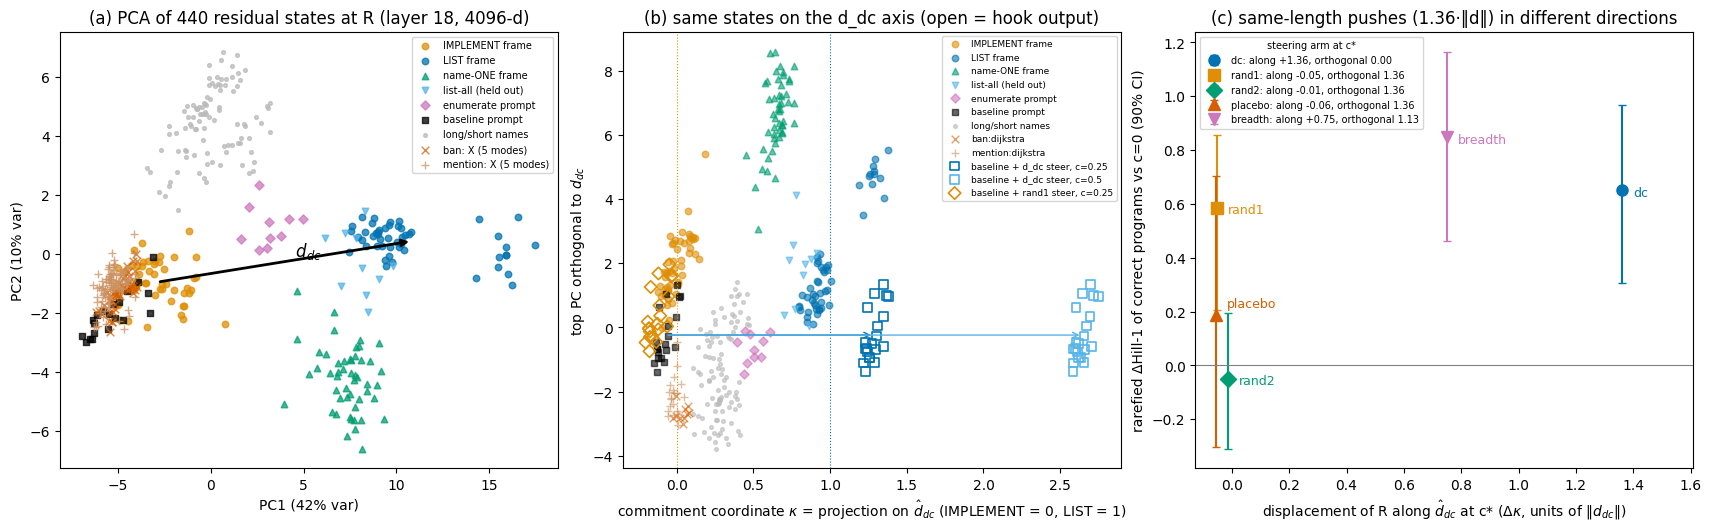

In [25]:
# ---- Figure 1: activation geometry at the read position R (layer L*), real Qwen3-8B residual states ----
t, li, L, cs = TASKS[0], STATE_LAYERS.index(lstar), lstar, cst[TASKS[0]]["c_star"]
groups = ["IMPLEMENT", "LIST", "ONE", "listall", "enumerate", "baseline", "LONGNAMES", "SHORTNAMES"] + \
         [f"ban:{x}" for x in CATALOGUE[t]] + [f"mention:{x}" for x in CATALOGUE[t]]
H = {g: load(t, g)[:, li] for g in groups}
STYLE = {"IMPLEMENT": ("#DE8F05", "o", "IMPLEMENT frame"), "LIST": ("#0173B2", "o", "LIST frame"),
         "ONE": ("#029E73", "^", "name-ONE frame"), "listall": ("#56B4E9", "v", "list-all (held out)"),
         "enumerate": ("#CC78BC", "D", "enumerate prompt"), "baseline": ("black", "s", "baseline prompt"),
         "LONGNAMES": ("#BBBBBB", ".", "long/short names"), "SHORTNAMES": ("#BBBBBB", ".", None),
         "ban": ("#D55E00", "x", "ban: X (5 modes)"), "mention": ("#CA9161", "+", "mention: X (5 modes)")}
allH = np.concatenate([H[g] for g in groups])
mu = allH.mean(0)
_, sv, Vt = np.linalg.svd(allH - mu, full_matrices=False)
dvec = DIRS[f"d_dc_{t}_L{L}"]
dnorm = float(np.linalg.norm(dvec))
dhat = dvec / dnorm
imp_mean = H["IMPLEMENT"].mean(0)


def kap(A):  # commitment coordinate: 0 = IMPLEMENT centroid, 1 = LIST centroid
    return (A - imp_mean) @ dhat / dnorm


resid = (allH - mu) - np.outer((allH - mu) @ dhat, dhat)
_, _, Vp = np.linalg.svd(resid, full_matrices=False)
u1 = Vp[0]  # main axis of variation orthogonal to d_dc

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
ax = axes[0]
for g in groups:
    col, mk, lab = STYLE[g.split(":")[0]]
    if g.startswith(("ban:", "mention:")) and not g.endswith(":" + modes[t]["X"]):
        lab = None  # one legend entry per kind of ban / mention prompt
    P = (H[g] - mu) @ Vt[:2].T
    ax.scatter(P[:, 0], P[:, 1], c=col, marker=mk, s=22 if mk not in ".+x" else 30, alpha=0.75, label=lab, lw=1)
pi, pl = (H["IMPLEMENT"].mean(0) - mu) @ Vt[:2].T, (H["LIST"].mean(0) - mu) @ Vt[:2].T
ax.annotate("", xy=pl, xytext=pi, arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
ax.text(*((pi + pl) / 2), "  $d_{dc}$", fontsize=12, va="bottom")
ev = sv ** 2 / (sv ** 2).sum()
ax.set_xlabel(f"PC1 ({100 * ev[0]:.0f}% var)")
ax.set_ylabel(f"PC2 ({100 * ev[1]:.0f}% var)")
ax.set_title(f"(a) PCA of {len(allH)} residual states at R (layer {L}, 4096-d)")
ax.legend(fontsize=7, loc="best")

ax = axes[1]
for g in groups:
    col, mk, lab = STYLE[g.split(":")[0]]
    if g.startswith(("ban:", "mention:")) and not g.endswith(":" + modes[t]["X"]):
        continue
    ax.scatter(kap(H[g]), (H[g] - mu) @ u1, c=col, marker=mk, s=22 if mk not in ".+x" else 30, alpha=0.6, lw=1,
               label=(lab if not g.startswith(("ban", "mention")) else g))
yb = (H["baseline"] - mu) @ u1
for c, col in ((cs, "#0173B2"), (0.5, "#56B4E9")):
    ks = kap(STEERED[("dc", c)])
    ax.scatter(ks, (STEERED[("dc", c)] - mu) @ u1, facecolors="none", edgecolors=col, marker="s", s=40, lw=1.2,
               label=f"baseline + d_dc steer, c={c:g}")
    ax.annotate("", xy=(ks.mean(), yb.mean()), xytext=(kap(H["baseline"]).mean(), yb.mean()),
                arrowprops=dict(arrowstyle="->", color=col, lw=1))
kr = kap(STEERED[("rand1", cs)])
ax.scatter(kr, (STEERED[("rand1", cs)] - mu) @ u1, facecolors="none", edgecolors="#DE8F05", marker="D", s=40, lw=1.2,
           label=f"baseline + rand1 steer, c={cs:g}")
ax.axvline(0, color="#DE8F05", lw=0.8, ls=":")
ax.axvline(1, color="#0173B2", lw=0.8, ls=":")
ax.set_xlabel(r"commitment coordinate $\kappa$ = projection on $\hat d_{dc}$ (IMPLEMENT = 0, LIST = 1)")
ax.set_ylabel(r"top PC orthogonal to $d_{dc}$")
ax.set_title("(b) same states on the d_dc axis (open = hook output)")
ax.legend(fontsize=6.5, loc="best")

ax = axes[2]
for k, (name, col, mk) in enumerate((("dc", "#0173B2", "o"), ("rand1", "#DE8F05", "s"), ("rand2", "#029E73", "D"),
                                     ("placebo", "#D55E00", "^"), ("breadth", "#CC78BC", "v"))):
    b = buy[t].get(f"steer:{name}:c={cs:g}:L={L}")
    gg = geo[(name, cs)]
    if not b or b.get("delta_hill_rarefied") is None:
        continue
    y, ci = b["delta_hill_rarefied"], b["ci90_rarefied_cluster"]
    ax.errorbar([gg["kappa_shift"]], [y], yerr=[[y - ci[0]], [ci[1] - y]], fmt=mk, color=col, capsize=3, ms=8,
                label=f"{name}: along {gg['kappa_shift']:+.2f}, orthogonal {gg['orthogonal']:.2f}")
    ax.annotate(name, (gg["kappa_shift"], y), xytext=(8, -4 + 10 * (name == "placebo")), textcoords="offset points",
                fontsize=9, color=col)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(right=max(g["kappa_shift"] for (nm, c), g in geo.items() if c == cs) + 0.25)
ax.set_xlabel(r"displacement of R along $\hat d_{dc}$ at c* ($\Delta\kappa$, units of $\|d_{dc}\|$)")
ax.set_ylabel("rarefied ΔHill-1 of correct programs vs c=0 (90% CI)")
ax.set_title(f"(c) same-length pushes ({geo[('dc', cs)]['total']:.2f}·‖d‖) in different directions")
ax.legend(fontsize=7, loc="best", title="steering arm at c*", title_fontsize=7)
plt.show()

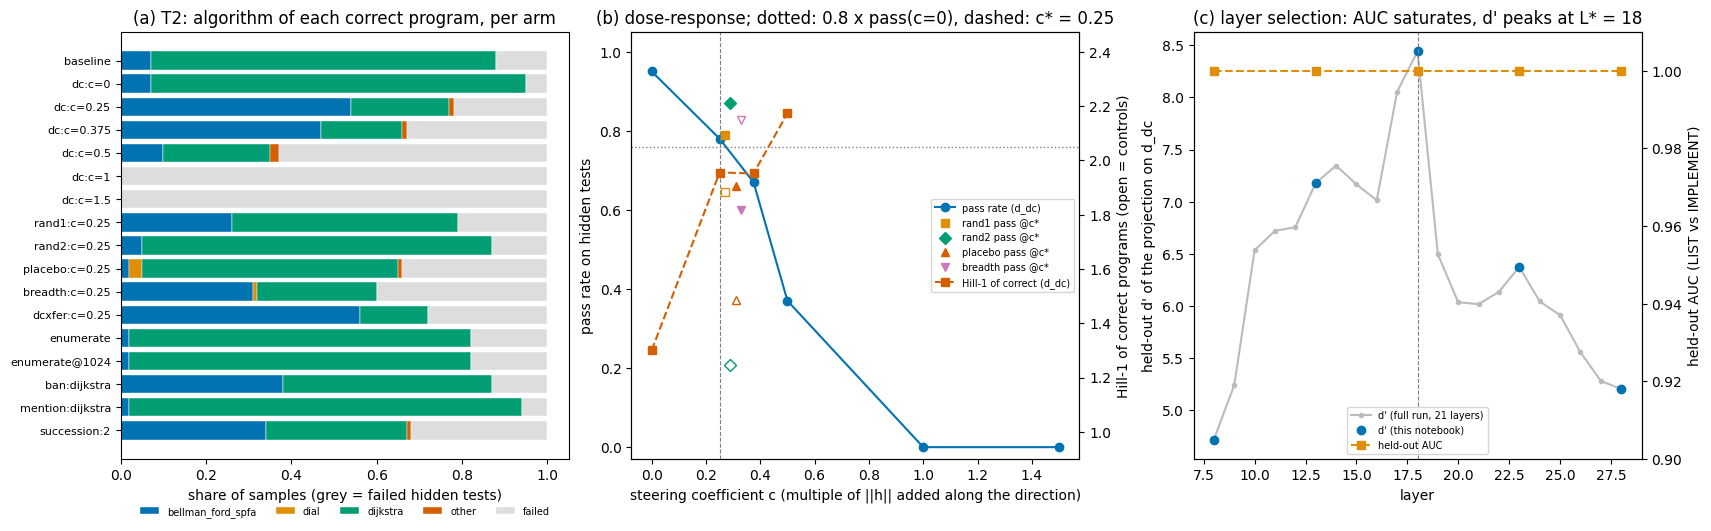

In [26]:
# ---- Figure 2: behaviour (what the model writes), dose-response and the layer profile ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
C = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#949494", "#ECE133", "#56B4E9"]
arms = [k for k in ORDER if f"{t}|{k}" in summ]
labs = sorted({k for a in arms for k in summ[f"{t}|{a}"]["label_counts_correct"]})
ax = axes[0]
left = [0.0] * len(arms)
for i, lab in enumerate(labs + ["failed"]):
    vals = []
    for a in arms:
        s = summ[f"{t}|{a}"]
        vals.append((s["n"] - s["n_correct"]) / s["n"] if lab == "failed" else s["label_counts_correct"].get(lab, 0) / s["n"])
    ax.barh(range(len(arms)), vals, left=left, color=("#DDDDDD" if lab == "failed" else C[i % len(C)]), label=lab,
            edgecolor="white", lw=0.3)
    left = [l + v for l, v in zip(left, vals)]
ax.set_yticks(range(len(arms)))
ax.set_yticklabels([a.replace(f":L={L}", "").replace("steer:", "") for a in arms], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("share of samples (grey = failed hidden tests)")
ax.set_title("(a) T2: algorithm of each correct program, per arm")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=5, frameon=False)

ax = axes[1]
cx = sorted(float(k) for k in cst[t]["pass_rates"])
P = [summ[f"{t}|steer:dc:c={c:g}:L={L}"]["pass_rate"] for c in cx]
Hh = [summ[f"{t}|steer:dc:c={c:g}:L={L}"]["hill_cc"]["hill1"] for c in cx]
ax.plot(cx, P, "o-", color=C[0], label="pass rate (d_dc)")
ax.axhline(cst[t]["threshold"], ls=":", color="grey", lw=1)
ax2 = ax.twinx()
ax2.plot(cx, [h if h is not None else np.nan for h in Hh], "s--", color=C[3], label="Hill-1 of correct (d_dc)")
for k, (nm, col, mk) in enumerate((("rand1", C[1], "s"), ("rand2", C[2], "D"), ("placebo", C[3], "^"),
                                   ("breadth", C[4], "v"))):
    s = summ.get(f"{t}|steer:{nm}:c={cs:g}:L={L}")
    if s:
        ax.plot([cs + 0.02 * (k + 1)], [s["pass_rate"]], mk, color=col, label=f"{nm} pass @c*")
        if s["hill_cc"]["hill1"] is not None:
            ax2.plot([cs + 0.02 * (k + 1)], [s["hill_cc"]["hill1"]], mk, color=col, mfc="none")
ax.axvline(cs, ls="--", color="grey", lw=0.8)
ax.set_xlabel("steering coefficient c (multiple of ||h|| added along the direction)")
ax.set_ylabel("pass rate on hidden tests")
ax2.set_ylabel("Hill-1 of correct programs (open = controls)")
ax.set_ylim(-0.03, 1.05)
ax2.set_ylim(0.9, max([h for h in Hh if h is not None] + [2.0]) + 0.3)
ax.set_title(f"(b) dose-response; dotted: 0.8 x pass(c=0), dashed: c* = {cs:g}")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="center right")

ax = axes[2]
ls_ = sorted(int(l) for l in REF["layer_selection_T2"])
ax.plot(ls_, [REF["layer_selection_T2"][str(l)]["dprime"] for l in ls_], ".-", color="#BBBBBB", label="d' (full run, 21 layers)")
ax.plot(SEL_LAYERS, [sel["per_layer"][str(l)][t]["dprime"] for l in SEL_LAYERS], "o", color=C[0], label="d' (this notebook)")
ax3 = ax.twinx()
ax3.plot(SEL_LAYERS, [sel["per_layer"][str(l)][t]["auc"] for l in SEL_LAYERS], "s--", color=C[1], label="held-out AUC")
ax3.set_ylim(0.9, 1.01)
ax3.set_ylabel("held-out AUC (LIST vs IMPLEMENT)")
ax.axvline(lstar, ls="--", color="grey", lw=0.8)
ax.set_xlabel("layer")
ax.set_ylabel("held-out d' of the projection on d_dc")
ax.set_title(f"(c) layer selection: AUC saturates, d' peaks at L* = {lstar}")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax3.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower center")
plt.show()

## Takeaways

* **The direction exists and is clean.** LIST and IMPLEMENT prompts separate perfectly at R on every layer (held-out AUC = 1). The direction is stable across paraphrase halves (cos ≈ 0.99). It is nearly orthogonal to the placebo naming direction. It aligns with the shift that the real *enumerate* prompt causes (cos ≈ 0.6).
* **Steering moves behaviour, but not specifically.** At c* = 0.25, d_dc pushes R about 1.4 LIST–IMPLEMENT distances along its own axis (Fig. 1b), and correct T2 programs flip from Dijkstra to Bellman-Ford (Fig. 2a). Fig. 1c shows the same-length pushes of the controls:
  * `rand1` is almost entirely *orthogonal* to d_dc, yet it buys nearly the same diversity gain;
  * `rand2` is just as orthogonal and buys none;
  * `breadth` (list vs name-one) is only half aligned with d_dc and buys the most;
  * the `placebo` buys a little.

  The gain does not follow the push's component along d_dc. Whatever "unlocks" Bellman-Ford is not the list-vs-implement axis. It looks more like a fragile commitment that some perturbations of ~25 % of the residual norm happen to break.
* **The gain is mostly a swap of the dominant algorithm.** Correct programs go from about 93 % Dijkstra (c = 0) to about 70 % Bellman-Ford (c*). Hill-1 rises from about 1.3 to about 2, out of 5 catalogue algorithms. (The pre-registered rule still calls this "flattens", because the CI of ΔHill lies above 0.) Hill-2 costs about 35 pass-rate points. Hill-3 is never reached before correctness collapses (pass rate 0 at c ≥ 1).
* **Prompts.** "List 10 approaches, then implement one" changes nothing. A ban buys more diversity at a far smaller pass-rate cost. Even so, many banned samples still use the banned algorithm, and on the commitment coordinate a ban moves R only ~0.05 of the LIST–IMPLEMENT distance (the enumerate positive control moves it ~0.58).
* **This demo vs the full run.** The HF steering arms are complete here (100 per arm), so with the original config values their numbers match the full run. The vLLM baseline has 100 of its 200 samples, so the prompt-arm and engine-check numbers differ slightly. T1, the second task, is not shipped: it is 100 % BFS everywhere.